In [1]:
print("FAIR-AI-P06 Project Setup Started")
print("Multimodal AI for Computational Drug Discovery")

FAIR-AI-P06 Project Setup Started
Multimodal AI for Computational Drug Discovery


In [2]:
import sys

print("Python Version:")
print(sys.version)

Python Version:
3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Basic libraries are working!")

NumPy version: 2.3.5
Pandas version: 2.3.3
Basic libraries are working!


In [1]:
import rdkit

print("RDKit is installed!")
print("RDKit version:", rdkit.__version__)

RDKit is installed!
RDKit version: 2026.03.1


In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("PyTorch is working!")

PyTorch version: 2.5.1+cpu
PyTorch is working!


In [2]:
import deepchem as dc
import torch
import rdkit

print("DeepChem version:", dc.__version__)
print("PyTorch version:", torch.__version__)
print("RDKit version:", rdkit.__version__)

print("\nAll AI/Drug Discovery libraries are working!")

DeepChem version: 2.8.0
PyTorch version: 2.5.1+cpu
RDKit version: 2026.03.1

All AI/Drug Discovery libraries are working!


In [3]:
import pandas as pd
import numpy as np
from rdkit import Chem

print("FAIR-AI-P06 Project Started Successfully!")
print("Molecular data processing is ready.")

FAIR-AI-P06 Project Started Successfully!
Molecular data processing is ready.


In [6]:
import requests

print("Requests is working!")
print("Requests version:", requests.__version__)

Requests is working!
Requests version: 2.34.2


In [7]:
import requests
import pandas as pd

url = "https://www.ebi.ac.uk/chembl/api/data/molecule.json?limit=10"

response = requests.get(url)

print("Status Code:", response.status_code)

data_json = response.json()

print("Keys in ChEMBL response:")
print(data_json.keys())

Status Code: 200
Keys in ChEMBL response:
dict_keys(['molecules', 'page_meta'])


In [8]:
molecules = data_json["molecules"]

data = pd.DataFrame(molecules)

print("Data downloaded successfully!")
print("Number of molecules:", len(data))

print("\nAvailable columns:")
print(data.columns.tolist())

Data downloaded successfully!
Number of molecules: 10

Available columns:
['atc_classifications', 'availability_type', 'biotherapeutic', 'black_box_warning', 'chemical_probe', 'chirality', 'cross_references', 'dosed_ingredient', 'first_approval', 'first_in_class', 'helm_notation', 'inorganic_flag', 'max_phase', 'molecule_chembl_id', 'molecule_hierarchy', 'molecule_properties', 'molecule_structures', 'molecule_synonyms', 'molecule_type', 'natural_product', 'oral', 'orphan', 'parenteral', 'polymer_flag', 'pref_name', 'prodrug', 'structure_type', 'therapeutic_flag', 'topical', 'usan_stem', 'usan_stem_definition', 'usan_substem', 'usan_year', 'veterinary', 'withdrawn_flag']


In [9]:
# Extract important molecular information

molecule_data = []

for molecule in molecules:
    molecule_id = molecule.get("molecule_chembl_id")
    molecule_name = molecule.get("pref_name")
    
    structures = molecule.get("molecule_structures")
    
    if structures:
        smiles = structures.get("canonical_smiles")
    else:
        smiles = None
    
    molecule_data.append({
        "ChEMBL_ID": molecule_id,
        "Molecule_Name": molecule_name,
        "SMILES": smiles
    })

molecule_df = pd.DataFrame(molecule_data)

print("Molecular dataset created!")
print("Number of records:", len(molecule_df))

molecule_df

Molecular dataset created!
Number of records: 10


,ChEMBL_ID,Molecule_Name,SMILES
0,CHEMBL6329,None,Cc1cc(-n2ncc(=O)[nH]c2=O)ccc1C(=O)c1ccccc1Cl
1,CHEMBL6328,None,Cc1cc(-n2ncc(=O)[nH]c2=O)ccc1C(=O)c1ccc(C#N)cc1
2,CHEMBL265667,None,Cc1cc(-n2ncc(=O)[nH]c2=O)cc(C)c1C(O)c1ccc(Cl)cc1
3,CHEMBL6362,None,Cc1ccc(C(=O)c2ccc(-n3ncc(=O)[nH]c3=O)cc2)cc1
4,CHEMBL267864,None,Cc1cc(-n2ncc(=O)[nH]c2=O)ccc1C(=O)c1ccc(Cl)cc1
5,CHEMBL6363,None,Cc1cc(-n2ncc(=O)[nH]c2=O)ccc1C(=O)c1ccccc1
6,CHEMBL6352,None,Cc1cc(Br)ccc1C(=O)c1ccc(-n2ncc(=O)[nH]c2=O)cc1Cl
7,CHEMBL268097,None,O=C(c1ccc(Cl)cc1Cl)c1ccc(-n2ncc(=O)[nH]c2=O)cc1Cl
8,CHEMBL266457,None,CS(=O)(=O)c1ccc(C(=O)c2ccc(-n3ncc(=O)[nH]c3=O)...
9,CHEMBL268556,None,c1cc2cc(c1)-c1cccc(c1)C[n+]1ccc(c3ccccc31)NCCC...


In [10]:
from rdkit import Chem

# Check whether each SMILES is valid

molecule_df["Valid_SMILES"] = molecule_df["SMILES"].apply(
    lambda x: Chem.MolFromSmiles(x) is not None if pd.notna(x) else False
)

print("SMILES validation completed!")

print("\nValid molecules:",
      molecule_df["Valid_SMILES"].sum())

print("Invalid molecules:",
      (~molecule_df["Valid_SMILES"]).sum())

molecule_df[["ChEMBL_ID", "SMILES", "Valid_SMILES"]]

SMILES validation completed!

Valid molecules: 10
Invalid molecules: 0


,ChEMBL_ID,SMILES,Valid_SMILES
0,CHEMBL6329,Cc1cc(-n2ncc(=O)[nH]c2=O)ccc1C(=O)c1ccccc1Cl,True
1,CHEMBL6328,Cc1cc(-n2ncc(=O)[nH]c2=O)ccc1C(=O)c1ccc(C#N)cc1,True
2,CHEMBL265667,Cc1cc(-n2ncc(=O)[nH]c2=O)cc(C)c1C(O)c1ccc(Cl)cc1,True
3,CHEMBL6362,Cc1ccc(C(=O)c2ccc(-n3ncc(=O)[nH]c3=O)cc2)cc1,True
4,CHEMBL267864,Cc1cc(-n2ncc(=O)[nH]c2=O)ccc1C(=O)c1ccc(Cl)cc1,True
5,CHEMBL6363,Cc1cc(-n2ncc(=O)[nH]c2=O)ccc1C(=O)c1ccccc1,True
6,CHEMBL6352,Cc1cc(Br)ccc1C(=O)c1ccc(-n2ncc(=O)[nH]c2=O)cc1Cl,True
7,CHEMBL268097,O=C(c1ccc(Cl)cc1Cl)c1ccc(-n2ncc(=O)[nH]c2=O)cc1Cl,True
8,CHEMBL266457,CS(=O)(=O)c1ccc(C(=O)c2ccc(-n3ncc(=O)[nH]c3=O)...,True
9,CHEMBL268556,c1cc2cc(c1)-c1cccc(c1)C[n+]1ccc(c3ccccc31)NCCC...,True


In [11]:
from rdkit import Chem

# Take the first molecule
smiles = molecule_df.loc[0, "SMILES"]

mol = Chem.MolFromSmiles(smiles)

print("SMILES:")
print(smiles)

print("\nNumber of atoms:", mol.GetNumAtoms())
print("Number of bonds:", mol.GetNumBonds())

print("\nAtoms:")
for atom in mol.GetAtoms():
    print(
        "Atom:", atom.GetIdx(),
        "| Element:", atom.GetSymbol(),
        "| Atomic Number:", atom.GetAtomicNum()
    )

SMILES:
Cc1cc(-n2ncc(=O)[nH]c2=O)ccc1C(=O)c1ccccc1Cl

Number of atoms: 24
Number of bonds: 26

Atoms:
Atom: 0 | Element: C | Atomic Number: 6
Atom: 1 | Element: C | Atomic Number: 6
Atom: 2 | Element: C | Atomic Number: 6
Atom: 3 | Element: C | Atomic Number: 6
Atom: 4 | Element: N | Atomic Number: 7
Atom: 5 | Element: N | Atomic Number: 7
Atom: 6 | Element: C | Atomic Number: 6
Atom: 7 | Element: C | Atomic Number: 6
Atom: 8 | Element: O | Atomic Number: 8
Atom: 9 | Element: N | Atomic Number: 7
Atom: 10 | Element: C | Atomic Number: 6
Atom: 11 | Element: O | Atomic Number: 8
Atom: 12 | Element: C | Atomic Number: 6
Atom: 13 | Element: C | Atomic Number: 6
Atom: 14 | Element: C | Atomic Number: 6
Atom: 15 | Element: C | Atomic Number: 6
Atom: 16 | Element: O | Atomic Number: 8
Atom: 17 | Element: C | Atomic Number: 6
Atom: 18 | Element: C | Atomic Number: 6
Atom: 19 | Element: C | Atomic Number: 6
Atom: 20 | Element: C | Atomic Number: 6
Atom: 21 | Element: C | Atomic Number: 6
Atom: 

In [12]:
print("Bonds in the molecule:\n")

for bond in mol.GetBonds():
    start_atom = bond.GetBeginAtomIdx()
    end_atom = bond.GetEndAtomIdx()
    bond_type = bond.GetBondType()

    print(
        "Atom", start_atom,
        "<-->", "Atom", end_atom,
        "| Bond:", bond_type
    )

Bonds in the molecule:

Atom 0 <--> Atom 1 | Bond: SINGLE
Atom 1 <--> Atom 2 | Bond: AROMATIC
Atom 2 <--> Atom 3 | Bond: AROMATIC
Atom 3 <--> Atom 4 | Bond: SINGLE
Atom 4 <--> Atom 5 | Bond: AROMATIC
Atom 5 <--> Atom 6 | Bond: AROMATIC
Atom 6 <--> Atom 7 | Bond: AROMATIC
Atom 7 <--> Atom 8 | Bond: DOUBLE
Atom 7 <--> Atom 9 | Bond: AROMATIC
Atom 9 <--> Atom 10 | Bond: AROMATIC
Atom 10 <--> Atom 11 | Bond: DOUBLE
Atom 3 <--> Atom 12 | Bond: AROMATIC
Atom 12 <--> Atom 13 | Bond: AROMATIC
Atom 13 <--> Atom 14 | Bond: AROMATIC
Atom 14 <--> Atom 15 | Bond: SINGLE
Atom 15 <--> Atom 16 | Bond: DOUBLE
Atom 15 <--> Atom 17 | Bond: SINGLE
Atom 17 <--> Atom 18 | Bond: AROMATIC
Atom 18 <--> Atom 19 | Bond: AROMATIC
Atom 19 <--> Atom 20 | Bond: AROMATIC
Atom 20 <--> Atom 21 | Bond: AROMATIC
Atom 21 <--> Atom 22 | Bond: AROMATIC
Atom 22 <--> Atom 23 | Bond: SINGLE
Atom 14 <--> Atom 1 | Bond: AROMATIC
Atom 22 <--> Atom 17 | Bond: AROMATIC
Atom 10 <--> Atom 4 | Bond: AROMATIC


In [13]:
print("Atom Features:\n")

for atom in mol.GetAtoms():
    print(
        "Atom:", atom.GetIdx(),
        "| Element:", atom.GetSymbol(),
        "| Atomic Number:", atom.GetAtomicNum(),
        "| Degree:", atom.GetDegree(),
        "| Hydrogens:", atom.GetTotalNumHs(),
        "| Formal Charge:", atom.GetFormalCharge(),
        "| Aromatic:", atom.GetIsAromatic()
    )

Atom Features:

Atom: 0 | Element: C | Atomic Number: 6 | Degree: 1 | Hydrogens: 3 | Formal Charge: 0 | Aromatic: False
Atom: 1 | Element: C | Atomic Number: 6 | Degree: 3 | Hydrogens: 0 | Formal Charge: 0 | Aromatic: True
Atom: 2 | Element: C | Atomic Number: 6 | Degree: 2 | Hydrogens: 1 | Formal Charge: 0 | Aromatic: True
Atom: 3 | Element: C | Atomic Number: 6 | Degree: 3 | Hydrogens: 0 | Formal Charge: 0 | Aromatic: True
Atom: 4 | Element: N | Atomic Number: 7 | Degree: 3 | Hydrogens: 0 | Formal Charge: 0 | Aromatic: True
Atom: 5 | Element: N | Atomic Number: 7 | Degree: 2 | Hydrogens: 0 | Formal Charge: 0 | Aromatic: True
Atom: 6 | Element: C | Atomic Number: 6 | Degree: 2 | Hydrogens: 1 | Formal Charge: 0 | Aromatic: True
Atom: 7 | Element: C | Atomic Number: 6 | Degree: 3 | Hydrogens: 0 | Formal Charge: 0 | Aromatic: True
Atom: 8 | Element: O | Atomic Number: 8 | Degree: 1 | Hydrogens: 0 | Formal Charge: 0 | Aromatic: False
Atom: 9 | Element: N | Atomic Number: 7 | Degree: 2 | H

In [14]:
atom_features = []

for atom in mol.GetAtoms():
    features = [
        atom.GetAtomicNum(),
        atom.GetDegree(),
        atom.GetTotalNumHs(),
        atom.GetFormalCharge(),
        int(atom.GetIsAromatic())
    ]
    
    atom_features.append(features)

atom_features_df = pd.DataFrame(
    atom_features,
    columns=[
        "Atomic_Number",
        "Degree",
        "Hydrogens",
        "Formal_Charge",
        "Aromatic"
    ]
)

print("Atom feature matrix created!")
print("Matrix shape:", atom_features_df.shape)

atom_features_df

Atom feature matrix created!
Matrix shape: (24, 5)


,Atomic_Number,Degree,Hydrogens,Formal_Charge,Aromatic
0,6,1,3,0,0
1,6,3,0,0,1
2,6,2,1,0,1
3,6,3,0,0,1
4,7,3,0,0,1
5,7,2,0,0,1
6,6,2,1,0,1
7,6,3,0,0,1
8,8,1,0,0,0
9,7,2,1,0,1


In [15]:
import deepchem as dc

# Convert the first molecule from SMILES into a DeepChem graph
smiles = molecule_df.loc[0, "SMILES"]

featurizer = dc.feat.ConvMolFeaturizer()

graph = featurizer.featurize([smiles])[0]

print("DeepChem graph created successfully!")
print("Number of atoms:", graph.get_num_atoms())

DeepChem graph created successfully!
Number of atoms: 24


In [16]:
import deepchem as dc

# Create DeepChem graph featurizer
featurizer = dc.feat.ConvMolFeaturizer()

# Convert all valid SMILES into molecular graphs
smiles_list = molecule_df["SMILES"].tolist()

graphs = featurizer.featurize(smiles_list)

print("DeepChem graph conversion completed!")
print("Total molecules:", len(graphs))

for i, graph in enumerate(graphs):
    print(
        "Molecule", i + 1,
        "| ChEMBL ID:", molecule_df.loc[i, "ChEMBL_ID"],
        "| Atoms:", graph.get_num_atoms()
    )

DeepChem graph conversion completed!
Total molecules: 10
Molecule 1 | ChEMBL ID: CHEMBL6329 | Atoms: 24
Molecule 2 | ChEMBL ID: CHEMBL6328 | Atoms: 25
Molecule 3 | ChEMBL ID: CHEMBL265667 | Atoms: 25
Molecule 4 | ChEMBL ID: CHEMBL6362 | Atoms: 23
Molecule 5 | ChEMBL ID: CHEMBL267864 | Atoms: 24
Molecule 6 | ChEMBL ID: CHEMBL6363 | Atoms: 23
Molecule 7 | ChEMBL ID: CHEMBL6352 | Atoms: 25
Molecule 8 | ChEMBL ID: CHEMBL268097 | Atoms: 25
Molecule 9 | ChEMBL ID: CHEMBL266457 | Atoms: 27
Molecule 10 | ChEMBL ID: CHEMBL268556 | Atoms: 46


In [17]:
# Check molecular graph features

first_graph = graphs[0]

print("Molecular graph feature analysis")
print("--------------------------------")

print("Number of atoms:",
      first_graph.get_num_atoms())

print("Atom feature matrix shape:",
      first_graph.get_atom_features().shape)

print("\nAtom feature matrix:")
print(first_graph.get_atom_features())

Molecular graph feature analysis
--------------------------------
Number of atoms: 24
Atom feature matrix shape: (24, 75)

Atom feature matrix:
[[1. 0. 0. ... 0. 1. 0.]
 [0. 0. 1. ... 0. 0. 0.]
 [0. 0. 1. ... 0. 0. 0.]
 ...
 [1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 0. 0.]]


In [20]:
# Check graph features for all molecules

print("Graph feature summary")
print("---------------------")

for i, graph in enumerate(graphs):

    print(
        "Molecule", i + 1,
        "| ChEMBL ID:", molecule_df.loc[i, "ChEMBL_ID"],
        "| Atoms:", graph.get_num_atoms(),
        "| Feature Shape:", graph.get_atom_features().shape
    )

Graph feature summary
---------------------
Molecule 1 | ChEMBL ID: CHEMBL6329 | Atoms: 24 | Feature Shape: (24, 75)
Molecule 2 | ChEMBL ID: CHEMBL6328 | Atoms: 25 | Feature Shape: (25, 75)
Molecule 3 | ChEMBL ID: CHEMBL265667 | Atoms: 25 | Feature Shape: (25, 75)
Molecule 4 | ChEMBL ID: CHEMBL6362 | Atoms: 23 | Feature Shape: (23, 75)
Molecule 5 | ChEMBL ID: CHEMBL267864 | Atoms: 24 | Feature Shape: (24, 75)
Molecule 6 | ChEMBL ID: CHEMBL6363 | Atoms: 23 | Feature Shape: (23, 75)
Molecule 7 | ChEMBL ID: CHEMBL6352 | Atoms: 25 | Feature Shape: (25, 75)
Molecule 8 | ChEMBL ID: CHEMBL268097 | Atoms: 25 | Feature Shape: (25, 75)
Molecule 9 | ChEMBL ID: CHEMBL266457 | Atoms: 27 | Feature Shape: (27, 75)
Molecule 10 | ChEMBL ID: CHEMBL268556 | Atoms: 46 | Feature Shape: (46, 75)


In [19]:
# Extract molecular feature information

molecular_embeddings_input = []

for graph in graphs:
    atom_features = graph.get_atom_features()
    
    # Average atom features to create one molecular representation
    molecular_vector = atom_features.mean(axis=0)
    
    molecular_embeddings_input.append(molecular_vector)

print("Molecular representations created!")
print("Number of molecules:", len(molecular_embeddings_input))
print("Features per molecule:", molecular_embeddings_input[0].shape[0])

Molecular representations created!
Number of molecules: 10
Features per molecule: 75


In [21]:
import numpy as np

# Convert molecular representations into a matrix
molecular_feature_matrix = np.array(molecular_embeddings_input)

print("Molecular feature matrix created!")
print("Matrix shape:", molecular_feature_matrix.shape)

print("\nFirst molecule feature vector:")
print(molecular_feature_matrix[0])

Molecular feature matrix created!
Matrix shape: (10, 75)

First molecule feature vector:
[0.70833333 0.125      0.125      0.         0.         0.
 0.         0.04166667 0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.20833333 0.41666667 0.375
 0.         0.         0.         0.         0.         0.
 0.         0.625      0.33333333 0.         0.04166667 0.
 0.         0.         0.         0.         0.         0.91666667
 0.08333333 0.         0.         0.75       0.58333333 0.375
 0.         0.04166667 0.        ]


In [22]:
import requests
import pandas as pd

# ChEMBL Activity API
url = "https://www.ebi.ac.uk/chembl/api/data/activity.json?limit=20"

response = requests.get(url)

print("Status Code:", response.status_code)

activity_data = response.json()

print("Keys in response:")
print(activity_data.keys())

Status Code: 200
Keys in response:
dict_keys(['activities', 'page_meta'])


In [23]:
# Extract activity records

activities = activity_data["activities"]

activity_df = pd.DataFrame(activities)

print("Activity dataset created!")
print("Number of activity records:", len(activity_df))

print("\nAvailable columns:")
print(activity_df.columns.tolist())

Activity dataset created!
Number of activity records: 20

Available columns:
['action_type', 'activity_comment', 'activity_id', 'activity_properties', 'assay_chembl_id', 'assay_description', 'assay_type', 'assay_variant_accession', 'assay_variant_mutation', 'bao_endpoint', 'bao_format', 'bao_label', 'canonical_smiles', 'data_validity_comment', 'data_validity_description', 'document_chembl_id', 'document_journal', 'document_year', 'ligand_efficiency', 'modality', 'molecule_chembl_id', 'molecule_pref_name', 'parent_molecule_chembl_id', 'pchembl_value', 'potential_duplicate', 'qudt_units', 'record_id', 'relation', 'src_id', 'standard_flag', 'standard_relation', 'standard_text_value', 'standard_type', 'standard_units', 'standard_upper_value', 'standard_value', 'target_chembl_id', 'target_organism', 'target_pref_name', 'target_tax_id', 'text_value', 'toid', 'type', 'units', 'uo_units', 'upper_value', 'value']


In [24]:
# Select important columns for our drug discovery project

important_columns = [
    "molecule_chembl_id",
    "target_chembl_id",
    "target_pref_name",
    "target_organism",
    "standard_type",
    "standard_value",
    "standard_units",
    "pchembl_value",
    "assay_chembl_id",
    "document_chembl_id"
]

activity_selected = activity_df[important_columns]

print("Important activity data selected!")
print("Dataset shape:", activity_selected.shape)

print("\nFirst 5 records:")
activity_selected.head()

Important activity data selected!
Dataset shape: (20, 10)

First 5 records:


,molecule_chembl_id,target_chembl_id,target_pref_name,target_organism,standard_type,standard_value,standard_units,pchembl_value,assay_chembl_id,document_chembl_id
0,CHEMBL113081,CHEMBL1806,DNA topoisomerase 2-alpha,Homo sapiens,IC50,100000.0,nM,NaN,CHEMBL663853,CHEMBL1137930
1,CHEMBL324340,CHEMBL3921,Heparanase,Homo sapiens,IC50,2500.0,nM,5.60,CHEMBL872937,CHEMBL1146658
2,CHEMBL324340,CHEMBL3879801,NON-PROTEIN TARGET,NaN,IC50,50000.0,nM,NaN,CHEMBL693237,CHEMBL1146658
3,CHEMBL109600,CHEMBL3921,Heparanase,Homo sapiens,IC50,9000.0,nM,5.05,CHEMBL872937,CHEMBL1146658
4,CHEMBL109600,CHEMBL3879801,NON-PROTEIN TARGET,NaN,IC50,NaN,nM,NaN,CHEMBL693238,CHEMBL1146658


In [29]:
import requests
import pandas as pd

# Get our 10 molecule IDs
molecule_ids = molecule_df["ChEMBL_ID"].tolist()

all_activities = []

for molecule_id in molecule_ids:

    url = "https://www.ebi.ac.uk/chembl/api/data/activity.json"

    params = {
        "molecule_chembl_id": molecule_id,
        "limit": 100
    }

    response = requests.get(url, params=params)

    if response.status_code == 200:
        data = response.json()
        all_activities.extend(data["activities"])

print("Activity data collected for our molecules!")
print("Total activity records:", len(all_activities))

Activity data collected for our molecules!
Total activity records: 18


In [30]:
# Convert collected activity records into a DataFrame

our_activity_df = pd.DataFrame(all_activities)

print("Our molecule activity dataset created!")
print("Number of records:", len(our_activity_df))
print("Number of columns:", len(our_activity_df.columns))

print("\nFirst 5 records:")
our_activity_df.head()

Our molecule activity dataset created!
Number of records: 18
Number of columns: 47

First 5 records:


,action_type,activity_comment,activity_id,activity_properties,assay_chembl_id,assay_description,assay_type,assay_variant_accession,assay_variant_mutation,bao_endpoint,...,target_organism,target_pref_name,target_tax_id,text_value,toid,type,units,uo_units,upper_value,value
0,None,None,205843,[],CHEMBL845014,Apparent pKa value was measured in 2:1 DMF/H2O.,P,None,None,BAO_0000179,...,NaN,No relevant target,NaN,None,None,pH1/2,NaN,NaN,None,7.08
1,None,None,205844,[],CHEMBL674772,Anticoccidial activity which controlled infect...,F,None,None,BAO_0000179,...,Eimeria tenella,Eimeria tenella,5802,None,None,MEC,p.p.m.,NaN,None,60.0
2,None,None,190321,[],CHEMBL845014,Apparent pKa value was measured in 2:1 DMF/H2O.,P,None,None,BAO_0000179,...,NaN,No relevant target,NaN,None,None,pH1/2,NaN,NaN,None,7.08
3,None,None,190322,[],CHEMBL674772,Anticoccidial activity which controlled infect...,F,None,None,BAO_0000179,...,Eimeria tenella,Eimeria tenella,5802,None,None,MEC,p.p.m.,NaN,None,125.0
4,None,None,207044,[],CHEMBL674772,Anticoccidial activity which controlled infect...,F,None,None,BAO_0000179,...,Eimeria tenella,Eimeria tenella,5802,None,None,MEC,p.p.m.,NaN,None,30.0


In [31]:
# Select important activity information

activity_clean = our_activity_df[
    [
        "molecule_chembl_id",
        "target_chembl_id",
        "target_pref_name",
        "target_organism",
        "standard_type",
        "standard_value",
        "standard_units",
        "pchembl_value",
        "assay_chembl_id",
        "document_chembl_id"
    ]
].copy()

print("Selected activity columns successfully!")

print("\nBefore filtering:")
print("Records:", len(activity_clean))

print("\nTarget names:")
print(activity_clean["target_pref_name"].value_counts(dropna=False))

Selected activity columns successfully!

Before filtering:
Records: 18

Target names:
target_pref_name
Eimeria tenella                                                    8
No relevant target                                                 4
Small conductance calcium-activated potassium channel              2
ADMET                                                              1
Eimeria necatrix                                                   1
Small conductance calcium-activated potassium channel protein 2    1
Rattus norvegicus                                                  1
Name: count, dtype: int64


In [32]:
# Inspect target and activity information

target_check = activity_clean[
    [
        "molecule_chembl_id",
        "target_chembl_id",
        "target_pref_name",
        "target_organism",
        "standard_type",
        "standard_value",
        "standard_units",
        "pchembl_value"
    ]
].copy()

print("Target and activity information:")
print("--------------------------------")

target_check

Target and activity information:
--------------------------------


,molecule_chembl_id,target_chembl_id,target_pref_name,target_organism,standard_type,standard_value,standard_units,pchembl_value
0,CHEMBL6329,CHEMBL2362975,No relevant target,NaN,pH1/2,7.08,NaN,NaN
1,CHEMBL6329,CHEMBL612854,Eimeria tenella,Eimeria tenella,MEC,60.0,p.p.m.,NaN
2,CHEMBL6328,CHEMBL2362975,No relevant target,NaN,pH1/2,7.08,NaN,NaN
3,CHEMBL6328,CHEMBL612854,Eimeria tenella,Eimeria tenella,MEC,125.0,p.p.m.,NaN
4,CHEMBL265667,CHEMBL612854,Eimeria tenella,Eimeria tenella,MEC,30.0,p.p.m.,NaN
5,CHEMBL6362,CHEMBL612854,Eimeria tenella,Eimeria tenella,MEC,250.0,p.p.m.,NaN
6,CHEMBL267864,CHEMBL2362975,No relevant target,NaN,pH1/2,7.6,NaN,NaN
7,CHEMBL267864,CHEMBL612558,ADMET,NaN,Plasma half-life,13.0,hr,NaN
8,CHEMBL267864,CHEMBL612854,Eimeria tenella,Eimeria tenella,MEC,8.0,p.p.m.,NaN
9,CHEMBL6363,CHEMBL2362975,No relevant target,NaN,pH1/2,7.02,NaN,NaN


In [33]:
# Filter for IC50 activity measurements

ic50_data = activity_clean[
    activity_clean["standard_type"] == "IC50"
].copy()

print("IC50 activity dataset created!")
print("Number of IC50 records:", len(ic50_data))

print("\nIC50 records:")
ic50_data

IC50 activity dataset created!
Number of IC50 records: 2

IC50 records:


,molecule_chembl_id,target_chembl_id,target_pref_name,target_organism,standard_type,standard_value,standard_units,pchembl_value,assay_chembl_id,document_chembl_id
14,CHEMBL268556,CHEMBL2547,Small conductance calcium-activated potassium ...,Rattus norvegicus,IC50,110.0,nM,6.96,CHEMBL805641,CHEMBL1151049
16,CHEMBL268556,CHEMBL2096673,Small conductance calcium-activated potassium ...,Rattus norvegicus,IC50,110.0,nM,6.96,CHEMBL785164,CHEMBL1133598


In [35]:
import requests
import pandas as pd

url = "https://www.ebi.ac.uk/chembl/api/data/target.json"

params = {
    "pref_name__icontains": "epidermal growth factor receptor",
    "limit": 20
}

response = requests.get(url, params=params)

print("Status Code:", response.status_code)

target_data = response.json()

targets = pd.DataFrame(target_data["targets"])

print("Number of targets found:", len(targets))

targets[
    [
        "target_chembl_id",
        "pref_name",
        "organism",
        "target_type"
    ]
]

Status Code: 200
Number of targets found: 16


,target_chembl_id,pref_name,organism,target_type
0,CHEMBL203,Epidermal growth factor receptor,Homo sapiens,SINGLE PROTEIN
1,CHEMBL3608,Epidermal growth factor receptor,Mus musculus,SINGLE PROTEIN
2,CHEMBL2111431,Epidermal growth factor receptor and ErbB2 (HE...,Homo sapiens,PROTEIN FAMILY
3,CHEMBL2363049,Epidermal growth factor receptor,Homo sapiens,PROTEIN FAMILY
4,CHEMBL4295760,Epidermal growth factor receptor substrate 15,Homo sapiens,SINGLE PROTEIN
5,CHEMBL4523680,Protein cereblon/Epidermal growth factor receptor,Homo sapiens,PROTEIN-PROTEIN INTERACTION
6,CHEMBL4523998,von Hippel-Lindau disease tumor suppressor/Epi...,Homo sapiens,PROTEIN-PROTEIN INTERACTION
7,CHEMBL4802031,Baculoviral IAP repeat-containing protein 2/Ep...,Homo sapiens,PROTEIN-PROTEIN INTERACTION
8,CHEMBL6066839,Microtubule-associated protein 1 light chain 3...,Homo sapiens,PROTEIN-PROTEIN INTERACTION
9,CHEMBL6066845,Glucose-induced degradation protein 4 homolog/...,Homo sapiens,PROTEIN-PROTEIN INTERACTION


In [36]:
import requests
import pandas as pd

target_id = "CHEMBL203"

url = "https://www.ebi.ac.uk/chembl/api/data/activity.json"

params = {
    "target_chembl_id": target_id,
    "standard_type": "IC50",
    "limit": 100
}

response = requests.get(url, params=params)

print("Status Code:", response.status_code)

egfr_data = response.json()

egfr_activities = pd.DataFrame(egfr_data["activities"])

print("EGFR IC50 records collected:", len(egfr_activities))
print("Number of columns:", len(egfr_activities.columns))

Status Code: 200
EGFR IC50 records collected: 100
Number of columns: 47


In [37]:
# Select important columns from EGFR IC50 dataset

egfr_clean = egfr_activities[
    [
        "molecule_chembl_id",
        "canonical_smiles",
        "target_chembl_id",
        "target_pref_name",
        "target_organism",
        "standard_type",
        "standard_value",
        "standard_units",
        "pchembl_value",
        "assay_chembl_id",
        "document_chembl_id"
    ]
].copy()

print("EGFR dataset cleaned for important columns!")
print("Dataset shape:", egfr_clean.shape)

print("\nSelected columns:")
print(egfr_clean.columns.tolist())

print("\nFirst 5 records:")
egfr_clean.head()

EGFR dataset cleaned for important columns!
Dataset shape: (100, 11)

Selected columns:
['molecule_chembl_id', 'canonical_smiles', 'target_chembl_id', 'target_pref_name', 'target_organism', 'standard_type', 'standard_value', 'standard_units', 'pchembl_value', 'assay_chembl_id', 'document_chembl_id']

First 5 records:


,molecule_chembl_id,canonical_smiles,target_chembl_id,target_pref_name,target_organism,standard_type,standard_value,standard_units,pchembl_value,assay_chembl_id,document_chembl_id
0,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,CHEMBL203,Epidermal growth factor receptor,Homo sapiens,IC50,41.0,nM,7.39,CHEMBL674637,CHEMBL1134862
1,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,CHEMBL203,Epidermal growth factor receptor,Homo sapiens,IC50,300.0,nM,6.52,CHEMBL621151,CHEMBL1134862
2,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,CHEMBL203,Epidermal growth factor receptor,Homo sapiens,IC50,7820.0,nM,5.11,CHEMBL615325,CHEMBL1134862
3,CHEMBL69960,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,CHEMBL203,Epidermal growth factor receptor,Homo sapiens,IC50,170.0,nM,6.77,CHEMBL674637,CHEMBL1134862
4,CHEMBL69960,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,CHEMBL203,Epidermal growth factor receptor,Homo sapiens,IC50,40.0,nM,7.40,CHEMBL621151,CHEMBL1134862


In [38]:
# Check missing values in EGFR dataset

print("Missing values in each column:")
print("--------------------------------")

missing_values = egfr_clean.isnull().sum()

print(missing_values)

Missing values in each column:
--------------------------------
molecule_chembl_id     0
canonical_smiles       0
target_chembl_id       0
target_pref_name       0
target_organism        0
standard_type          0
standard_value         6
standard_units         0
pchembl_value         44
assay_chembl_id        0
document_chembl_id     0
dtype: int64


In [39]:
# Remove records where IC50 value is missing

egfr_cleaned = egfr_clean.dropna(
    subset=["standard_value"]
).copy()

print("Data cleaning completed!")
print("Original records:", len(egfr_clean))
print("Records after removing missing IC50:", len(egfr_cleaned))
print("Records removed:", len(egfr_clean) - len(egfr_cleaned))

Data cleaning completed!
Original records: 100
Records after removing missing IC50: 94
Records removed: 6


In [40]:
# Check unique molecules

total_records = len(egfr_cleaned)
unique_molecules = egfr_cleaned["molecule_chembl_id"].nunique()

print("Total cleaned activity records:", total_records)
print("Unique molecules:", unique_molecules)
print("Repeated activity records:", total_records - unique_molecules)

Total cleaned activity records: 94
Unique molecules: 79
Repeated activity records: 15


In [41]:
# Check available pChEMBL values

print("Available pChEMBL values:")
print("-------------------------")

print("Total records:", len(egfr_cleaned))
print(
    "Records with pChEMBL:",
    egfr_cleaned["pchembl_value"].notna().sum()
)
print(
    "Records without pChEMBL:",
    egfr_cleaned["pchembl_value"].isna().sum()
)

print("\nFirst 10 available pChEMBL values:")
print(
    egfr_cleaned["pchembl_value"]
    .dropna()
    .head(10)
    .to_list()
)

Available pChEMBL values:
-------------------------
Total records: 94
Records with pChEMBL: 56
Records without pChEMBL: 38

First 10 available pChEMBL values:
['7.39', '6.52', '5.11', '6.77', '7.40', '6.36', '5.03', '4.02', '5.28', '6.90']


In [42]:
# Check IC50 measurement units

print("IC50 units in cleaned dataset:")
print("--------------------------------")

print(egfr_cleaned["standard_units"].value_counts(dropna=False))

IC50 units in cleaned dataset:
--------------------------------
standard_units
nM    94
Name: count, dtype: int64


In [44]:
# Convert IC50 values from text to numeric

egfr_cleaned["standard_value"] = pd.to_numeric(
    egfr_cleaned["standard_value"],
    errors="coerce"
)

print("standard_value converted to numeric!")
print("Data type:", egfr_cleaned["standard_value"].dtype)

standard_value converted to numeric!
Data type: float64


In [45]:
# Final statistical summary of EGFR IC50 values

print("EGFR IC50 Activity Summary")
print("--------------------------")

print("Minimum IC50:", egfr_cleaned["standard_value"].min(), "nM")
print("Maximum IC50:", egfr_cleaned["standard_value"].max(), "nM")
print("Mean IC50:", round(egfr_cleaned["standard_value"].mean(), 2), "nM")
print("Median IC50:", egfr_cleaned["standard_value"].median(), "nM")

EGFR IC50 Activity Summary
--------------------------
Minimum IC50: 0.45 nM
Maximum IC50: 6500000.0 nM
Mean IC50: 355047.76 nM
Median IC50: 13425.0 nM


In [46]:
import numpy as np

# Convert IC50 from nM to M
egfr_cleaned["IC50_M"] = egfr_cleaned["standard_value"] * 1e-9

# Calculate pIC50
egfr_cleaned["pIC50"] = -np.log10(egfr_cleaned["IC50_M"])

print("pIC50 calculation completed!")

print("\nFirst 10 pIC50 values:")
print(
    egfr_cleaned[
        ["molecule_chembl_id", "standard_value", "IC50_M", "pIC50"]
    ].head(10)
)

pIC50 calculation completed!

First 10 pIC50 values:
  molecule_chembl_id  standard_value        IC50_M     pIC50
0        CHEMBL68920            41.0  4.100000e-08  7.387216
1        CHEMBL68920           300.0  3.000000e-07  6.522879
2        CHEMBL68920          7820.0  7.820000e-06  5.106793
3        CHEMBL69960           170.0  1.700000e-07  6.769551
4        CHEMBL69960            40.0  4.000000e-08  7.397940
5        CHEMBL69960           440.0  4.400000e-07  6.356547
6       CHEMBL137635          9300.0  9.300000e-06  5.031517
7       CHEMBL306988        500000.0  5.000000e-04  3.301030
8        CHEMBL66879       3000000.0  3.000000e-03  2.522879
9        CHEMBL77085         96000.0  9.600000e-05  4.017729


In [47]:
# Check pIC50 range

print("EGFR pIC50 Summary")
print("------------------")

print("Minimum pIC50:", round(egfr_cleaned["pIC50"].min(), 2))
print("Maximum pIC50:", round(egfr_cleaned["pIC50"].max(), 2))
print("Mean pIC50:", round(egfr_cleaned["pIC50"].mean(), 2))
print("Median pIC50:", round(egfr_cleaned["pIC50"].median(), 2))

EGFR pIC50 Summary
------------------
Minimum pIC50: 2.19
Maximum pIC50: 9.35
Mean pIC50: 5.07
Median pIC50: 4.87


In [48]:
from rdkit import Chem

# Validate molecular SMILES

egfr_cleaned["Valid_SMILES"] = egfr_cleaned["canonical_smiles"].apply(
    lambda x: Chem.MolFromSmiles(x) is not None
    if pd.notna(x) else False
)

print("SMILES validation completed!")
print("Total records:", len(egfr_cleaned))
print("Valid SMILES:", egfr_cleaned["Valid_SMILES"].sum())
print("Invalid SMILES:", (~egfr_cleaned["Valid_SMILES"]).sum())

SMILES validation completed!
Total records: 94
Valid SMILES: 94
Invalid SMILES: 0


In [49]:
from rdkit import Chem

# Convert SMILES into RDKit molecular objects

egfr_cleaned["Mol"] = egfr_cleaned["canonical_smiles"].apply(
    Chem.MolFromSmiles
)

print("Molecular graph objects created!")
print("Total molecules:", len(egfr_cleaned))

Molecular graph objects created!
Total molecules: 94


In [50]:
# Inspect the first molecule

first_mol = egfr_cleaned.iloc[0]["Mol"]

print("First molecule:")
print("----------------")
print("Molecule ID:", egfr_cleaned.iloc[0]["molecule_chembl_id"])
print("Number of atoms:", first_mol.GetNumAtoms())
print("Number of bonds:", first_mol.GetNumBonds())

print("\nAtoms:")
for atom in first_mol.GetAtoms():
    print(
        "Atom:", atom.GetIdx(),
        "| Element:", atom.GetSymbol(),
        "| Atomic Number:", atom.GetAtomicNum()
    )

print("\nBonds:")
for bond in first_mol.GetBonds():
    print(
        "Bond:", bond.GetIdx(),
        "| From:", bond.GetBeginAtomIdx(),
        "| To:", bond.GetEndAtomIdx(),
        "| Type:", bond.GetBondType()
    )

First molecule:
----------------
Molecule ID: CHEMBL68920
Number of atoms: 27
Number of bonds: 30

Atoms:
Atom: 0 | Element: C | Atomic Number: 6
Atom: 1 | Element: C | Atomic Number: 6
Atom: 2 | Element: C | Atomic Number: 6
Atom: 3 | Element: C | Atomic Number: 6
Atom: 4 | Element: C | Atomic Number: 6
Atom: 5 | Element: C | Atomic Number: 6
Atom: 6 | Element: C | Atomic Number: 6
Atom: 7 | Element: C | Atomic Number: 6
Atom: 8 | Element: C | Atomic Number: 6
Atom: 9 | Element: O | Atomic Number: 8
Atom: 10 | Element: N | Atomic Number: 7
Atom: 11 | Element: C | Atomic Number: 6
Atom: 12 | Element: N | Atomic Number: 7
Atom: 13 | Element: C | Atomic Number: 6
Atom: 14 | Element: N | Atomic Number: 7
Atom: 15 | Element: C | Atomic Number: 6
Atom: 16 | Element: N | Atomic Number: 7
Atom: 17 | Element: C | Atomic Number: 6
Atom: 18 | Element: C | Atomic Number: 6
Atom: 19 | Element: C | Atomic Number: 6
Atom: 20 | Element: C | Atomic Number: 6
Atom: 21 | Element: F | Atomic Number: 9
At

In [51]:
# Check all molecular graphs

print("Total molecules:", len(egfr_cleaned))
print("Total molecular graphs:", egfr_cleaned["Mol"].notna().sum())

print("\nGraph information:")
print("-------------------")

for i in range(5):
    mol = egfr_cleaned.iloc[i]["Mol"]
    
    print(
        i + 1,
        "| Molecule:",
        egfr_cleaned.iloc[i]["molecule_chembl_id"],
        "| Atoms:",
        mol.GetNumAtoms(),
        "| Bonds:",
        mol.GetNumBonds()
    )

Total molecules: 94
Total molecular graphs: 94

Graph information:
-------------------
1 | Molecule: CHEMBL68920 | Atoms: 27 | Bonds: 30
2 | Molecule: CHEMBL68920 | Atoms: 27 | Bonds: 30
3 | Molecule: CHEMBL68920 | Atoms: 27 | Bonds: 30
4 | Molecule: CHEMBL69960 | Atoms: 34 | Bonds: 38
5 | Molecule: CHEMBL69960 | Atoms: 34 | Bonds: 38


In [52]:
# Create basic atom features for the first molecule

mol = egfr_cleaned.iloc[0]["Mol"]

atom_features = []

for atom in mol.GetAtoms():
    features = [
        atom.GetAtomicNum(),
        atom.GetDegree(),
        atom.GetTotalNumHs(),
        atom.GetFormalCharge(),
        int(atom.GetIsAromatic())
    ]
    
    atom_features.append(features)

print("Molecule:", egfr_cleaned.iloc[0]["molecule_chembl_id"])
print("Number of atoms:", len(atom_features))
print("Number of features per atom:", len(atom_features[0]))

print("\nFirst 10 atom feature vectors:")
for i, feature in enumerate(atom_features[:10]):
    print("Atom", i, ":", feature)

Molecule: CHEMBL68920
Number of atoms: 27
Number of features per atom: 5

First 10 atom feature vectors:
Atom 0 : [6, 1, 3, 0, 0]
Atom 1 : [6, 3, 0, 0, 1]
Atom 2 : [6, 2, 1, 0, 1]
Atom 3 : [6, 3, 0, 0, 1]
Atom 4 : [6, 1, 3, 0, 0]
Atom 5 : [6, 3, 0, 0, 1]
Atom 6 : [6, 2, 1, 0, 0]
Atom 7 : [6, 3, 0, 0, 0]
Atom 8 : [6, 3, 0, 0, 0]
Atom 9 : [8, 1, 0, 0, 0]


In [53]:
# Create atom features for all 94 molecules

all_atom_features = []

for mol in egfr_cleaned["Mol"]:
    
    molecule_features = []
    
    for atom in mol.GetAtoms():
        features = [
            atom.GetAtomicNum(),
            atom.GetDegree(),
            atom.GetTotalNumHs(),
            atom.GetFormalCharge(),
            int(atom.GetIsAromatic())
        ]
        
        molecule_features.append(features)
    
    all_atom_features.append(molecule_features)

print("Total molecules processed:", len(all_atom_features))

print("\nFirst molecule:")
print("Number of atoms:", len(all_atom_features[0]))
print("Features per atom:", len(all_atom_features[0][0]))

print("\nSecond molecule:")
print("Number of atoms:", len(all_atom_features[1]))
print("Features per atom:", len(all_atom_features[1][0]))

Total molecules processed: 94

First molecule:
Number of atoms: 27
Features per atom: 5

Second molecule:
Number of atoms: 27
Features per atom: 5


In [54]:
# Extract bond information from the first molecule

mol = egfr_cleaned.iloc[0]["Mol"]

bond_features = []

for bond in mol.GetBonds():
    features = [
        bond.GetBeginAtomIdx(),
        bond.GetEndAtomIdx(),
        int(bond.GetBondTypeAsDouble()),
        int(bond.GetIsAromatic())
    ]
    
    bond_features.append(features)

print("Molecule:", egfr_cleaned.iloc[0]["molecule_chembl_id"])
print("Number of bonds:", len(bond_features))
print("Features per bond:", len(bond_features[0]))

print("\nFirst 10 bond feature vectors:")

for i, feature in enumerate(bond_features[:10]):
    print("Bond", i, ":", feature)

Molecule: CHEMBL68920
Number of bonds: 30
Features per bond: 4

First 10 bond feature vectors:
Bond 0 : [0, 1, 1, 0]
Bond 1 : [1, 2, 1, 1]
Bond 2 : [2, 3, 1, 1]
Bond 3 : [3, 4, 1, 0]
Bond 4 : [3, 5, 1, 1]
Bond 5 : [5, 6, 1, 0]
Bond 6 : [6, 7, 2, 0]
Bond 7 : [7, 8, 1, 0]
Bond 8 : [8, 9, 2, 0]
Bond 9 : [8, 10, 1, 0]


In [55]:
# Create bond features for all 94 molecules

all_bond_features = []

for mol in egfr_cleaned["Mol"]:
    
    molecule_bonds = []
    
    for bond in mol.GetBonds():
        features = [
            bond.GetBeginAtomIdx(),
            bond.GetEndAtomIdx(),
            int(bond.GetBondTypeAsDouble()),
            int(bond.GetIsAromatic())
        ]
        
        molecule_bonds.append(features)
    
    all_bond_features.append(molecule_bonds)

print("Total molecules processed:", len(all_bond_features))

print("\nFirst molecule:")
print("Number of bonds:", len(all_bond_features[0]))
print("Features per bond:", len(all_bond_features[0][0]))

print("\nSecond molecule:")
print("Number of bonds:", len(all_bond_features[1]))
print("Features per bond:", len(all_bond_features[1][0]))

Total molecules processed: 94

First molecule:
Number of bonds: 30
Features per bond: 4

Second molecule:
Number of bonds: 30
Features per bond: 4


In [56]:
# Check PyTorch Geometric

try:
    import torch_geometric
    
    print("PyTorch Geometric is installed!")
    print("Version:", torch_geometric.__version__)

except ImportError:
    print("PyTorch Geometric is NOT installed.")

PyTorch Geometric is NOT installed.


In [57]:
import torch
import torch_geometric

print("PyTorch version:", torch.__version__)
print("PyTorch Geometric version:", torch_geometric.__version__)

print("\nPyTorch Geometric is working!")

C:\Users\Asus\.conda\envs\fairai\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch version: 2.5.1+cpu
PyTorch Geometric version: 2.8.0.post1

PyTorch Geometric is working!


In [58]:
# Convert the first molecule into a PyTorch Geometric graph

import torch
from torch_geometric.data import Data

mol = egfr_cleaned.iloc[0]["Mol"]

# -----------------------------
# Node features
# -----------------------------

node_features = []

for atom in mol.GetAtoms():
    features = [
        atom.GetAtomicNum(),
        atom.GetDegree(),
        atom.GetTotalNumHs(),
        atom.GetFormalCharge(),
        int(atom.GetIsAromatic())
    ]
    
    node_features.append(features)

x = torch.tensor(node_features, dtype=torch.float)


# -----------------------------
# Edge information
# -----------------------------

edge_list = []

for bond in mol.GetBonds():
    start = bond.GetBeginAtomIdx()
    end = bond.GetEndAtomIdx()
    
    # Add both directions
    edge_list.append([start, end])
    edge_list.append([end, start])

edge_index = torch.tensor(edge_list, dtype=torch.long).t().contiguous()


# -----------------------------
# Create graph
# -----------------------------

graph = Data(
    x=x,
    edge_index=edge_index
)

print("Molecule:", egfr_cleaned.iloc[0]["molecule_chembl_id"])
print("Graph:")
print(graph)

print("\nNode feature shape:", graph.x.shape)
print("Edge index shape:", graph.edge_index.shape)

Molecule: CHEMBL68920
Graph:
Data(x=[27, 5], edge_index=[2, 60])

Node feature shape: torch.Size([27, 5])
Edge index shape: torch.Size([2, 60])


In [59]:
# Convert all 94 molecules into PyTorch Geometric graphs

import torch
from torch_geometric.data import Data

graph_dataset = []

for mol in egfr_cleaned["Mol"]:
    
    # -----------------------------
    # Node features
    # -----------------------------
    
    node_features = []
    
    for atom in mol.GetAtoms():
        features = [
            atom.GetAtomicNum(),
            atom.GetDegree(),
            atom.GetTotalNumHs(),
            atom.GetFormalCharge(),
            int(atom.GetIsAromatic())
        ]
        
        node_features.append(features)
    
    x = torch.tensor(node_features, dtype=torch.float)
    
    
    # -----------------------------
    # Edge information
    # -----------------------------
    
    edge_list = []
    
    for bond in mol.GetBonds():
        start = bond.GetBeginAtomIdx()
        end = bond.GetEndAtomIdx()
        
        # Both directions
        edge_list.append([start, end])
        edge_list.append([end, start])
    
    edge_index = torch.tensor(
        edge_list,
        dtype=torch.long
    ).t().contiguous()
    
    
    # -----------------------------
    # Create graph
    # -----------------------------
    
    graph = Data(
        x=x,
        edge_index=edge_index
    )
    
    graph_dataset.append(graph)


print("Total graphs created:", len(graph_dataset))

print("\nFirst graph:")
print(graph_dataset[0])

print("\nLast graph:")
print(graph_dataset[-1])

Total graphs created: 94

First graph:
Data(x=[27, 5], edge_index=[2, 60])

Last graph:
Data(x=[35, 5], edge_index=[2, 78])


In [60]:
# Attach pIC50 values to the molecular graphs

for i, graph in enumerate(graph_dataset):
    graph.y = torch.tensor(
        [egfr_cleaned.iloc[i]["pIC50"]],
        dtype=torch.float
    )

print("pIC50 values attached to all graphs!")

print("\nFirst graph:")
print(graph_dataset[0])

print("\nFirst molecule pIC50:")
print(graph_dataset[0].y.item())

pIC50 values attached to all graphs!

First graph:
Data(x=[27, 5], edge_index=[2, 60], y=[1])

First molecule pIC50:
7.387216091156006


In [61]:
# Split molecular graphs into training and testing data

from torch_geometric.loader import DataLoader
from sklearn.model_selection import train_test_split

# Create indices
indices = list(range(len(graph_dataset)))

# 80% training, 20% testing
train_indices, test_indices = train_test_split(
    indices,
    test_size=0.20,
    random_state=42
)

# Create datasets
train_dataset = [graph_dataset[i] for i in train_indices]
test_dataset = [graph_dataset[i] for i in test_indices]

print("Total graphs:", len(graph_dataset))
print("Training graphs:", len(train_dataset))
print("Testing graphs:", len(test_dataset))

Total graphs: 94
Training graphs: 75
Testing graphs: 19


In [62]:
# Define the GNN model

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, global_mean_pool


class GNNModel(nn.Module):

    def __init__(self):
        super().__init__()

        # First GNN layer
        self.conv1 = GCNConv(5, 32)

        # Second GNN layer
        self.conv2 = GCNConv(32, 64)

        # Fully connected layers
        self.fc1 = nn.Linear(64, 32)
        self.fc2 = nn.Linear(32, 1)


    def forward(self, x, edge_index, batch):

        # GNN layer 1
        x = self.conv1(x, edge_index)
        x = F.relu(x)

        # GNN layer 2
        x = self.conv2(x, edge_index)
        x = F.relu(x)

        # Convert node features into one molecule-level representation
        x = global_mean_pool(x, batch)

        # Fully connected layers
        x = self.fc1(x)
        x = F.relu(x)

        x = self.fc2(x)

        return x


# Create model
model = GNNModel()

print(model)

GNNModel(
  (conv1): GCNConv(5, 32)
  (conv2): GCNConv(32, 64)
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (fc2): Linear(in_features=32, out_features=1, bias=True)
)


In [63]:
# Prepare DataLoader, Loss Function and Optimizer

from torch_geometric.loader import DataLoader

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

# Loss function
criterion = nn.MSELoss()

# Optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Training DataLoader created!")
print("Testing DataLoader created!")

print("\nBatch size:", 16)
print("Loss function:", criterion)
print("Optimizer:", optimizer)

Training DataLoader created!
Testing DataLoader created!

Batch size: 16
Loss function: MSELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [64]:
# Train the GNN model

num_epochs = 50

for epoch in range(num_epochs):

    # Training mode
    model.train()

    total_loss = 0

    for batch in train_loader:

        # Clear previous gradients
        optimizer.zero_grad()

        # Make prediction
        prediction = model(
            batch.x,
            batch.edge_index,
            batch.batch
        )

        # Calculate error
        loss = criterion(
            prediction,
            batch.y.view(-1, 1)
        )

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        total_loss += loss.item()

    # Average loss
    average_loss = total_loss / len(train_loader)

    # Display progress
    if (epoch + 1) % 5 == 0:
        print(
            "Epoch:",
            epoch + 1,
            "| Training Loss:",
            round(average_loss, 4)
        )

Epoch: 5 | Training Loss: 14.6574
Epoch: 10 | Training Loss: 3.3763
Epoch: 15 | Training Loss: 3.0465
Epoch: 20 | Training Loss: 2.9418
Epoch: 25 | Training Loss: 2.9485
Epoch: 30 | Training Loss: 2.9689
Epoch: 35 | Training Loss: 2.88
Epoch: 40 | Training Loss: 2.9463
Epoch: 45 | Training Loss: 2.7875
Epoch: 50 | Training Loss: 2.8907


In [65]:
# Test the trained GNN model

model.eval()

actual_values = []
predicted_values = []

with torch.no_grad():

    for batch in test_loader:

        # Predict pIC50
        prediction = model(
            batch.x,
            batch.edge_index,
            batch.batch
        )

        # Store actual and predicted values
        actual_values.extend(
            batch.y.view(-1).tolist()
        )

        predicted_values.extend(
            prediction.view(-1).tolist()
        )

print("Testing completed!")

print("\nNumber of actual values:", len(actual_values))
print("Number of predicted values:", len(predicted_values))

print("\nFirst 5 predictions:")

for i in range(min(5, len(actual_values))):
    print(
        "Actual:",
        round(actual_values[i], 3),
        "| Predicted:",
        round(predicted_values[i], 3)
    )

Testing completed!

Number of actual values: 19
Number of predicted values: 19

First 5 predictions:
Actual: 2.854 | Predicted: 4.668
Actual: 5.523 | Predicted: 4.844
Actual: 4.328 | Predicted: 4.84
Actual: 3.079 | Predicted: 4.881
Actual: 7.387 | Predicted: 5.216


In [66]:
# Evaluate the GNN model

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(
    actual_values,
    predicted_values
)

rmse = np.sqrt(
    mean_squared_error(
        actual_values,
        predicted_values
    )
)

r2 = r2_score(
    actual_values,
    predicted_values
)

print("GNN Model Evaluation")
print("---------------------")

print("MAE  :", round(mae, 4))
print("RMSE :", round(rmse, 4))
print("R²   :", round(r2, 4))

GNN Model Evaluation
---------------------
MAE  : 1.433
RMSE : 1.6702
R²   : 0.0918


In [67]:
# Create molecule-level train/test split

from sklearn.model_selection import train_test_split

# Get unique molecule IDs
unique_molecules = egfr_cleaned["molecule_chembl_id"].unique()

# Split unique molecules
train_molecules, test_molecules = train_test_split(
    unique_molecules,
    test_size=0.20,
    random_state=42
)

# Select graph indices according to molecule ID
train_indices = [
    i for i, molecule_id in enumerate(egfr_cleaned["molecule_chembl_id"])
    if molecule_id in train_molecules
]

test_indices = [
    i for i, molecule_id in enumerate(egfr_cleaned["molecule_chembl_id"])
    if molecule_id in test_molecules
]

# Create new datasets
train_dataset = [graph_dataset[i] for i in train_indices]
test_dataset = [graph_dataset[i] for i in test_indices]

print("Total unique molecules:", len(unique_molecules))
print("Training unique molecules:", len(train_molecules))
print("Testing unique molecules:", len(test_molecules))

print("\nTraining graphs:", len(train_dataset))
print("Testing graphs:", len(test_dataset))

Total unique molecules: 79
Training unique molecules: 63
Testing unique molecules: 16

Training graphs: 75
Testing graphs: 19


In [68]:
# Create DataLoaders for the molecule-level split

from torch_geometric.loader import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

print("New DataLoaders created successfully!")

print("Training graphs:", len(train_dataset))
print("Testing graphs:", len(test_dataset))

New DataLoaders created successfully!
Training graphs: 75
Testing graphs: 19


In [69]:
# Create a fresh GNN model for molecule-level split

model = GNNModel()

# Loss function
criterion = nn.MSELoss()

# Optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Fresh GNN model created!")
print("\nModel:")
print(model)

Fresh GNN model created!

Model:
GNNModel(
  (conv1): GCNConv(5, 32)
  (conv2): GCNConv(32, 64)
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (fc2): Linear(in_features=32, out_features=1, bias=True)
)


In [70]:
# Train the fresh GNN model

num_epochs = 50

for epoch in range(num_epochs):

    model.train()
    total_loss = 0

    for batch in train_loader:

        # Reset gradients
        optimizer.zero_grad()

        # GNN prediction
        prediction = model(
            batch.x,
            batch.edge_index,
            batch.batch
        )

        # Calculate loss
        loss = criterion(
            prediction,
            batch.y.view(-1, 1)
        )

        # Backpropagation
        loss.backward()

        # Update model parameters
        optimizer.step()

        total_loss += loss.item()

    # Average training loss
    average_loss = total_loss / len(train_loader)

    # Show progress
    if (epoch + 1) % 5 == 0:
        print(
            "Epoch:",
            epoch + 1,
            "| Training Loss:",
            round(average_loss, 4)
        )

Epoch: 5 | Training Loss: 17.298
Epoch: 10 | Training Loss: 3.2263
Epoch: 15 | Training Loss: 3.0227
Epoch: 20 | Training Loss: 2.915
Epoch: 25 | Training Loss: 2.8495
Epoch: 30 | Training Loss: 2.8564
Epoch: 35 | Training Loss: 2.7939
Epoch: 40 | Training Loss: 2.8287
Epoch: 45 | Training Loss: 2.7657
Epoch: 50 | Training Loss: 2.807


In [71]:
model.eval()

actual_values = []
predicted_values = []

with torch.no_grad():

    for batch in test_loader:

        prediction = model(
            batch.x,
            batch.edge_index,
            batch.batch
        )

        actual_values.extend(
            batch.y.view(-1).tolist()
        )

        predicted_values.extend(
            prediction.view(-1).tolist()
        )

print("Testing completed!")

print("Number of actual values:", len(actual_values))
print("Number of predicted values:", len(predicted_values))

print("\nFirst 5 predictions:")

for actual, predicted in zip(actual_values[:5], predicted_values[:5]):
    print(
        "Actual:",
        round(actual, 3),
        "| Predicted:",
        round(predicted, 3)
    )

Testing completed!
Number of actual values: 19
Number of predicted values: 19

First 5 predictions:
Actual: 7.387 | Predicted: 5.335
Actual: 6.523 | Predicted: 5.335
Actual: 5.107 | Predicted: 5.335
Actual: 2.523 | Predicted: 5.029
Actual: 3.204 | Predicted: 4.915


In [72]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(
    actual_values,
    predicted_values
)

rmse = np.sqrt(
    mean_squared_error(
        actual_values,
        predicted_values
    )
)

r2 = r2_score(
    actual_values,
    predicted_values
)

print("GNN Model Evaluation")
print("---------------------")
print("MAE  :", round(mae, 4))
print("RMSE :", round(rmse, 4))
print("R²   :", round(r2, 4))

GNN Model Evaluation
---------------------
MAE  : 1.4809
RMSE : 1.6893
R²   : 0.1459


In [73]:
# Check ChEMBL activity relation values

print("Relation values:")
print(egfr_activities["relation"].value_counts())

print("\nUnique relation values:")
print(egfr_activities["relation"].unique())

Relation values:
relation
=    85
>     9
Name: count, dtype: int64

Unique relation values:
<StringArray>
['=', '>', nan]
Length: 3, dtype: str


In [74]:
# Check records with relation ">" in our EGFR dataset

greater_than_records = egfr_cleaned[
    egfr_cleaned["molecule_chembl_id"].isin(
        egfr_activities.loc[
            egfr_activities["relation"] == ">",
            "molecule_chembl_id"
        ]
    )
]

print("Number of records with relation '>':", len(greater_than_records))

print("\nThese records are:")
print(
    greater_than_records[
        [
            "molecule_chembl_id",
            "standard_value",
            "standard_units",
            "pIC50"
        ]
    ].to_string(index=False)
)

Number of records with relation '>': 10

These records are:
molecule_chembl_id  standard_value standard_units    pIC50
       CHEMBL77724       1250000.0             nM 2.903090
      CHEMBL420385        625000.0             nM 3.204120
       CHEMBL76983       1250000.0             nM 2.903090
       CHEMBL77280       1250000.0             nM 2.903090
       CHEMBL78302        250000.0             nM 3.602060
       CHEMBL68258         20000.0             nM 4.698970
       CHEMBL77456       1250000.0             nM 2.903090
      CHEMBL305194            29.0             nM 7.537602
      CHEMBL305194          5000.0             nM 5.301030
      CHEMBL305194         50000.0             nM 4.301030


In [76]:
# Detailed relation summary

print("Total records:", len(egfr_activities))

print("\nRelation summary:")
print(
    egfr_activities["relation"].value_counts(dropna=False)
)

print("\nUnique molecules:")
print(
    egfr_activities["molecule_chembl_id"].nunique()
)

print("\nDuplicate molecule records:")
print(
    egfr_activities["molecule_chembl_id"].duplicated().sum()
)

Total records: 100

Relation summary:
relation
=      85
>       9
NaN     6
Name: count, dtype: int64

Unique molecules:
83

Duplicate molecule records:
17


In [77]:
# Check exact (=) EGFR records

exact_records = egfr_activities[
    egfr_activities["relation"] == "="
].copy()

print("Exact (=) records:", len(exact_records))

print(
    "Unique molecules:",
    exact_records["molecule_chembl_id"].nunique()
)

print(
    "Repeated molecule records:",
    exact_records["molecule_chembl_id"].duplicated().sum()
)

print("\nFirst 10 exact records:")

print(
    exact_records[
        [
            "molecule_chembl_id",
            "standard_value",
            "standard_units",
            "pchembl_value"
        ]
    ].head(10).to_string(index=False)
)

Exact (=) records: 85
Unique molecules: 72
Repeated molecule records: 13

First 10 exact records:
molecule_chembl_id standard_value standard_units pchembl_value
       CHEMBL68920           41.0             nM          7.39
       CHEMBL68920          300.0             nM          6.52
       CHEMBL68920         7820.0             nM          5.11
       CHEMBL69960          170.0             nM          6.77
       CHEMBL69960           40.0             nM          7.40
       CHEMBL69960          440.0             nM          6.36
      CHEMBL137635         9300.0             nM          5.03
      CHEMBL306988       500000.0             nM           NaN
       CHEMBL66879      3000000.0             nM           NaN
       CHEMBL77085        96000.0             nM          4.02


In [78]:
# Create final clean EGFR dataset using exact IC50 measurements

egfr_final = egfr_activities[
    egfr_activities["relation"] == "="
].copy()

# Remove rows where IC50 value is missing
egfr_final = egfr_final.dropna(
    subset=["standard_value", "canonical_smiles"]
).copy()

# Make sure IC50 is numeric
egfr_final["standard_value"] = pd.to_numeric(
    egfr_final["standard_value"],
    errors="coerce"
)

# Remove any values that could not be converted
egfr_final = egfr_final.dropna(
    subset=["standard_value"]
).copy()

# Convert IC50 from nM to M
egfr_final["IC50_M"] = (
    egfr_final["standard_value"] * 1e-9
)

# Calculate pIC50
egfr_final["pIC50"] = -np.log10(
    egfr_final["IC50_M"]
)

print("Final clean dataset created!")

print("Total records:", len(egfr_final))

print(
    "Unique molecules:",
    egfr_final["molecule_chembl_id"].nunique()
)

print(
    "Missing pIC50:",
    egfr_final["pIC50"].isna().sum()
)

print("\nFirst 5 records:")

print(
    egfr_final[
        [
            "molecule_chembl_id",
            "standard_value",
            "standard_units",
            "pIC50"
        ]
    ].head().to_string(index=False)
)

Final clean dataset created!
Total records: 85
Unique molecules: 72
Missing pIC50: 0

First 5 records:
molecule_chembl_id  standard_value standard_units    pIC50
       CHEMBL68920            41.0             nM 7.387216
       CHEMBL68920           300.0             nM 6.522879
       CHEMBL68920          7820.0             nM 5.106793
       CHEMBL69960           170.0             nM 6.769551
       CHEMBL69960            40.0             nM 7.397940


In [80]:
# Create RDKit molecule objects for the final clean dataset

egfr_final["Mol"] = egfr_final["canonical_smiles"].apply(
    Chem.MolFromSmiles
)

print("RDKit molecules created!")

print("Total molecules:", len(egfr_final))

print(
    "Valid molecules:",
    egfr_final["Mol"].notna().sum()
)

print(
    "Invalid molecules:",
    egfr_final["Mol"].isna().sum()
)

RDKit molecules created!
Total molecules: 85
Valid molecules: 85
Invalid molecules: 0


In [82]:
# Create molecular graphs from the final clean dataset

graph_dataset_final = []

for i, mol in enumerate(egfr_final["Mol"]):

    node_features = []

    # Create node features for every atom
    for atom in mol.GetAtoms():

        features = [
            atom.GetAtomicNum(),
            atom.GetDegree(),
            atom.GetTotalNumHs(),
            atom.GetFormalCharge(),
            int(atom.GetIsAromatic())
        ]

        node_features.append(features)

    x = torch.tensor(
        node_features,
        dtype=torch.float
    )

    # Create edges from chemical bonds
    edge_list = []

    for bond in mol.GetBonds():

        start = bond.GetBeginAtomIdx()
        end = bond.GetEndAtomIdx()

        # Add both directions
        edge_list.append([start, end])
        edge_list.append([end, start])

    edge_index = torch.tensor(
        edge_list,
        dtype=torch.long
    ).t().contiguous()

    # Create PyTorch Geometric graph
    graph = Data(
        x=x,
        edge_index=edge_index
    )

    # Attach pIC50
    graph.y = torch.tensor(
        [egfr_final.iloc[i]["pIC50"]],
        dtype=torch.float
    )

    graph_dataset_final.append(graph)


print("Final molecular graphs created!")

print("Total graphs:", len(graph_dataset_final))

print("\nFirst graph:")
print(graph_dataset_final[0])

print("\nFirst graph pIC50:")
print(graph_dataset_final[0].y.item())

Final molecular graphs created!
Total graphs: 85

First graph:
Data(x=[27, 5], edge_index=[2, 60], y=[1])

First graph pIC50:
7.387216091156006


In [83]:
# Create molecule-level train-test split

unique_molecules_final = egfr_final[
    "molecule_chembl_id"
].unique()

train_molecules_final, test_molecules_final = train_test_split(
    unique_molecules_final,
    test_size=0.20,
    random_state=42
)

train_indices_final = [
    i
    for i, molecule_id in enumerate(
        egfr_final["molecule_chembl_id"]
    )
    if molecule_id in train_molecules_final
]

test_indices_final = [
    i
    for i, molecule_id in enumerate(
        egfr_final["molecule_chembl_id"]
    )
    if molecule_id in test_molecules_final
]

train_dataset_final = [
    graph_dataset_final[i]
    for i in train_indices_final
]

test_dataset_final = [
    graph_dataset_final[i]
    for i in test_indices_final
]

print("Molecule-level split created!")

print(
    "Total unique molecules:",
    len(unique_molecules_final)
)

print(
    "Training unique molecules:",
    len(train_molecules_final)
)

print(
    "Testing unique molecules:",
    len(test_molecules_final)
)

print(
    "Training graphs:",
    len(train_dataset_final)
)

print(
    "Testing graphs:",
    len(test_dataset_final)
)

Molecule-level split created!
Total unique molecules: 72
Training unique molecules: 57
Testing unique molecules: 15
Training graphs: 64
Testing graphs: 21


In [84]:
from torch_geometric.loader import DataLoader

# Create DataLoaders

train_loader_final = DataLoader(
    train_dataset_final,
    batch_size=16,
    shuffle=True
)

test_loader_final = DataLoader(
    test_dataset_final,
    batch_size=16,
    shuffle=False
)

print("DataLoaders created successfully!")

print("Training batches:", len(train_loader_final))
print("Testing batches:", len(test_loader_final))

DataLoaders created successfully!
Training batches: 4
Testing batches: 2


In [85]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import GCNConv, global_mean_pool


class FinalGNNModel(nn.Module):

    def __init__(self):
        super().__init__()

        # First Graph Convolution Layer
        self.conv1 = GCNConv(5, 32)

        # Second Graph Convolution Layer
        self.conv2 = GCNConv(32, 64)

        # Fully Connected Layers
        self.fc1 = nn.Linear(64, 32)
        self.fc2 = nn.Linear(32, 1)

    def forward(self, x, edge_index, batch):

        # Graph Convolution 1
        x = self.conv1(x, edge_index)
        x = F.relu(x)

        # Graph Convolution 2
        x = self.conv2(x, edge_index)
        x = F.relu(x)

        # Convert node features into one molecular representation
        x = global_mean_pool(x, batch)

        # Prediction layers
        x = self.fc1(x)
        x = F.relu(x)

        x = self.fc2(x)

        return x


# Create model
model_final = FinalGNNModel()

print("Final GNN model created successfully!")
print(model_final)

Final GNN model created successfully!
FinalGNNModel(
  (conv1): GCNConv(5, 32)
  (conv2): GCNConv(32, 64)
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (fc2): Linear(in_features=32, out_features=1, bias=True)
)


In [86]:
import torch.optim as optim

# Loss function
criterion = nn.MSELoss()

# Optimizer
optimizer = optim.Adam(
    model_final.parameters(),
    lr=0.001
)

# Number of training epochs
num_epochs = 50

print("Starting GNN training...")

for epoch in range(num_epochs):

    model_final.train()

    total_loss = 0

    for batch in train_loader_final:

        # Clear previous gradients
        optimizer.zero_grad()

        # Model prediction
        predictions = model_final(
            batch.x,
            batch.edge_index,
            batch.batch
        )

        # Actual pIC50 values
        targets = batch.y.view(-1, 1)

        # Calculate loss
        loss = criterion(
            predictions,
            targets
        )

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader_final)

    # Print every 5 epochs
    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch {epoch + 1:02d} | "
            f"Training Loss: {average_loss:.4f}"
        )

print("GNN training completed!")

Starting GNN training...
Epoch 05 | Training Loss: 23.1294
Epoch 10 | Training Loss: 8.6872
Epoch 15 | Training Loss: 3.3173
Epoch 20 | Training Loss: 2.8365
Epoch 25 | Training Loss: 2.7842
Epoch 30 | Training Loss: 2.7759
Epoch 35 | Training Loss: 2.7626
Epoch 40 | Training Loss: 2.7501
Epoch 45 | Training Loss: 2.7412
Epoch 50 | Training Loss: 2.7293
GNN training completed!


In [87]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Put model in evaluation mode
model_final.eval()

actual_values = []
predicted_values = []

# No gradient calculation during testing
with torch.no_grad():

    for batch in test_loader_final:

        predictions = model_final(
            batch.x,
            batch.edge_index,
            batch.batch
        )

        targets = batch.y.view(-1, 1)

        # Store actual and predicted values
        actual_values.extend(
            targets.cpu().numpy().flatten()
        )

        predicted_values.extend(
            predictions.cpu().numpy().flatten()
        )

# Convert to NumPy arrays
actual_values = np.array(actual_values)
predicted_values = np.array(predicted_values)

# Calculate evaluation metrics
mae = mean_absolute_error(
    actual_values,
    predicted_values
)

rmse = np.sqrt(
    mean_squared_error(
        actual_values,
        predicted_values
    )
)

r2 = r2_score(
    actual_values,
    predicted_values
)

print("GNN Test Results")
print("-------------------------")
print(f"Test samples: {len(actual_values)}")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")


GNN Test Results
-------------------------
Test samples: 21
MAE  : 1.6072
RMSE : 1.8379
R²   : 0.1147


In [88]:
import requests
import pandas as pd

# PubMed search
search_url = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/esearch.fcgi"

params = {
    "db": "pubmed",
    "term": "EGFR",
    "retmode": "json",
    "retmax": 20
}

response = requests.get(
    search_url,
    params=params
)

print("Status Code:", response.status_code)

search_data = response.json()

pmid_list = search_data["esearchresult"]["idlist"]

print("Number of PubMed papers found:", len(pmid_list))
print("First few PMID:", pmid_list[:5])

Status Code: 200
Number of PubMed papers found: 20
First few PMID: ['42823866', '42823821', '42823779', '42823758', '42820303']


In [89]:
# Fetch details of PubMed papers

fetch_url = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi"

params = {
    "db": "pubmed",
    "id": ",".join(pmid_list),
    "retmode": "xml"
}

response = requests.get(
    fetch_url,
    params=params
)

print("Status Code:", response.status_code)

xml_text = response.text

print("PubMed data downloaded successfully!")
print("Downloaded characters:", len(xml_text))

Status Code: 200
PubMed data downloaded successfully!
Downloaded characters: 433350


In [90]:
import xml.etree.ElementTree as ET

# Parse PubMed XML
root = ET.fromstring(xml_text)

literature_data = []

for article in root.findall(".//PubmedArticle"):

    # PMID
    pmid_element = article.find(".//PMID")
    pmid = pmid_element.text if pmid_element is not None else ""

    # Title
    title_element = article.find(".//ArticleTitle")
    title = "".join(title_element.itertext()) if title_element is not None else ""

    # Abstract
    abstract_parts = article.findall(".//Abstract/AbstractText")

    abstract = " ".join(
        "".join(part.itertext())
        for part in abstract_parts
    )

    # Store only papers that have an abstract
    if title and abstract:
        literature_data.append({
            "PMID": pmid,
            "Title": title,
            "Abstract": abstract
        })

# Create DataFrame
literature_df = pd.DataFrame(literature_data)

print("Literature dataset created!")
print("Number of papers with abstracts:", len(literature_df))

print("\nColumns:")
print(literature_df.columns.tolist())

print("\nFirst paper:")
print("PMID:", literature_df.iloc[0]["PMID"])
print("Title:", literature_df.iloc[0]["Title"])
print("Abstract:", literature_df.iloc[0]["Abstract"][:500])

Literature dataset created!
Number of papers with abstracts: 18

Columns:
['PMID', 'Title', 'Abstract']

First paper:
PMID: 42823866
Title: Robot-assisted advancing spiral flap pyeloplasty for complex ureteropelvic junction obstruction and ureteral atresia: a preliminary experience in 27 patients.
Abstract: Long-segment ureteropelvic junction obstruction (UPJO) (typically 12≥3 cm) and ureteral atresia present major reconstructive challenges due to fixed-length limitations of conventional flap techniques. This study evaluates the feasibility and safety of a robot-assisted advancing spiral flap pyeloplasty (RASFP) with dynamically adjustable flap design as a proof-of-concept for complex cases. A single-center retrospective study (August 2022-July 2025) included 27 patients with long-segment UPJO (med


In [91]:
# Search PubMed specifically for Epidermal Growth Factor Receptor

search_url = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/esearch.fcgi"

params = {
    "db": "pubmed",
    "term": '"epidermal growth factor receptor"[Title/Abstract]',
    "retmode": "json",
    "retmax": 30
}

response = requests.get(
    search_url,
    params=params
)

print("Status Code:", response.status_code)

search_data_egfr = response.json()

pmid_list_egfr = search_data_egfr[
    "esearchresult"
]["idlist"]

print(
    "Number of EGFR-related papers found:",
    len(pmid_list_egfr)
)

print(
    "First few PMID:",
    pmid_list_egfr[:5]
)

Status Code: 200
Number of EGFR-related papers found: 30
First few PMID: ['42820285', '42820043', '42823535', '42823184', '42823157']


In [92]:
# Fetch EGFR-related PubMed papers

fetch_url = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi"

params = {
    "db": "pubmed",
    "id": ",".join(pmid_list_egfr),
    "retmode": "xml"
}

response_egfr = requests.get(
    fetch_url,
    params=params
)

print("Status Code:", response_egfr.status_code)

xml_text_egfr = response_egfr.text

print("EGFR literature data downloaded successfully!")
print("Downloaded characters:", len(xml_text_egfr))

Status Code: 200
EGFR literature data downloaded successfully!
Downloaded characters: 555046


In [93]:
import xml.etree.ElementTree as ET

# Parse EGFR PubMed XML
root_egfr = ET.fromstring(xml_text_egfr)

egfr_literature_data = []

for article in root_egfr.findall(".//PubmedArticle"):

    # PMID
    pmid_element = article.find(".//PMID")

    pmid = (
        pmid_element.text
        if pmid_element is not None
        else ""
    )

    # Title
    title_element = article.find(".//ArticleTitle")

    title = (
        "".join(title_element.itertext())
        if title_element is not None
        else ""
    )

    # Abstract
    abstract_parts = article.findall(
        ".//Abstract/AbstractText"
    )

    abstract = " ".join(
        "".join(part.itertext())
        for part in abstract_parts
    )

    # Store papers having both title and abstract
    if title and abstract:

        egfr_literature_data.append({
            "PMID": pmid,
            "Title": title,
            "Abstract": abstract
        })

# Create DataFrame
egfr_literature_df = pd.DataFrame(
    egfr_literature_data
)

print("EGFR literature dataset created!")
print(
    "Number of papers with abstracts:",
    len(egfr_literature_df)
)

print("\nColumns:")
print(
    egfr_literature_df.columns.tolist()
)

print("\nFirst paper:")
print(
    "PMID:",
    egfr_literature_df.iloc[0]["PMID"]
)

print(
    "Title:",
    egfr_literature_df.iloc[0]["Title"]
)

print(
    "Abstract:",
    egfr_literature_df.iloc[0]["Abstract"][:500]
)

EGFR literature dataset created!
Number of papers with abstracts: 29

Columns:
['PMID', 'Title', 'Abstract']

First paper:
PMID: 42820285
Title: Breast cancer immunogenicity as a spectrum: evolving concepts and therapeutic implications.
Abstract: Immunotherapy has revolutionized the therapeutic landscape for many cancers, but its application in solid tumors has lagged. There is now evidence that immunotherapy can improve outcomes in triple-negative breast cancer, but hormone receptor-positive (HR+) breast cancer has traditionally been considered immunologically cold. However, emerging evidence challenges this binary paradigm, suggesting that a biologically relevant subset of HR+/human epidermal growth factor receptor 2-negative (HER2-) t


In [94]:
# Filter literature specifically mentioning EGFR

egfr_literature_df["Text"] = (
    egfr_literature_df["Title"].fillna("")
    + " "
    + egfr_literature_df["Abstract"].fillna("")
)

egfr_literature_filtered = egfr_literature_df[
    egfr_literature_df["Text"].str.contains(
        r"\bEGFR\b|epidermal growth factor receptor",
        case=False,
        regex=True,
        na=False
    )
].copy()

print("Original papers:", len(egfr_literature_df))

print(
    "EGFR-specific papers:",
    len(egfr_literature_filtered)
)

print("\nFirst 5 titles:\n")

for i, title in enumerate(
    egfr_literature_filtered["Title"].head(5),
    start=1
):
    print(f"{i}. {title}")

Original papers: 29
EGFR-specific papers: 29

First 5 titles:

1. Breast cancer immunogenicity as a spectrum: evolving concepts and therapeutic implications.
2. Phosphoglycerate kinase 1 cooperates with the AP2 complex to promote endocytosis.
3. Predicting Chemoresistance in HER2-low Breast Cancer: Histologic Grade, MRI Non-mass Enhancement, and Clinical T Stage.
4. Molecular Profiling of Archival Tonsillar Squamous Cell Carcinoma in a Korean Pre-HPV-vaccination Cohort.
5. Clinical Outcomes and Prognostic Factors of ABCP Therapy in EGFR-mutated NSCLC in the Osimertinib Era.


In [95]:
import re

# Make a copy of the filtered literature dataset
literature_nlp_df = egfr_literature_filtered.copy()

# Combine title and abstract
literature_nlp_df["Text"] = (
    literature_nlp_df["Title"].fillna("")
    + " "
    + literature_nlp_df["Abstract"].fillna("")
)

# Text cleaning function
def clean_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text)

    # Remove leading and trailing spaces
    text = text.strip()

    return text


# Apply cleaning
literature_nlp_df["Clean_Text"] = (
    literature_nlp_df["Text"].apply(clean_text)
)

print("Literature text cleaning completed!")

print("Total papers:", len(literature_nlp_df))

print("\nColumns:")
print(literature_nlp_df.columns.tolist())

print("\nOriginal text:")
print(literature_nlp_df.iloc[0]["Text"][:300])

print("\nCleaned text:")
print(literature_nlp_df.iloc[0]["Clean_Text"][:300])

Literature text cleaning completed!
Total papers: 29

Columns:
['PMID', 'Title', 'Abstract', 'Text', 'Clean_Text']

Original text:
Breast cancer immunogenicity as a spectrum: evolving concepts and therapeutic implications. Immunotherapy has revolutionized the therapeutic landscape for many cancers, but its application in solid tumors has lagged. There is now evidence that immunotherapy can improve outcomes in triple-negative br

Cleaned text:
breast cancer immunogenicity as a spectrum: evolving concepts and therapeutic implications. immunotherapy has revolutionized the therapeutic landscape for many cancers, but its application in solid tumors has lagged. there is now evidence that immunotherapy can improve outcomes in triple-negative br


In [1]:
from sentence_transformers import SentenceTransformer

literature_model = SentenceTransformer("all-MiniLM-L6-v2")

print("Literature model loaded successfully!")

C:\Users\Asus\.conda\envs\fairai\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\Asus\.conda\envs\fairai\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Asus\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to act

Literature model loaded successfully!


In [5]:
import requests
import pandas as pd
import xml.etree.ElementTree as ET

search_url = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/esearch.fcgi"

params = {
    "db": "pubmed",
    "term": '"epidermal growth factor receptor"[Title/Abstract]',
    "retmode": "json",
    "retmax": 30
}

response = requests.get(search_url, params=params)
search_data_egfr = response.json()

pmid_list_egfr = search_data_egfr["esearchresult"]["idlist"]

print("EGFR papers found:", len(pmid_list_egfr))

EGFR papers found: 30


In [6]:
fetch_url = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi"

params = {
    "db": "pubmed",
    "id": ",".join(pmid_list_egfr),
    "retmode": "xml"
}

response_egfr = requests.get(fetch_url, params=params)

xml_text_egfr = response_egfr.text

print("Status Code:", response_egfr.status_code)
print("Downloaded characters:", len(xml_text_egfr))

Status Code: 200
Downloaded characters: 555046


In [7]:
root_egfr = ET.fromstring(xml_text_egfr)

egfr_literature_data = []

for article in root_egfr.findall(".//PubmedArticle"):

    pmid_element = article.find(".//PMID")
    pmid = pmid_element.text if pmid_element is not None else ""

    title_element = article.find(".//ArticleTitle")
    title = "".join(title_element.itertext()) if title_element is not None else ""

    abstract_parts = article.findall(".//Abstract/AbstractText")

    abstract = " ".join(
        "".join(part.itertext())
        for part in abstract_parts
    )

    if title and abstract:
        egfr_literature_data.append({
            "PMID": pmid,
            "Title": title,
            "Abstract": abstract
        })

egfr_literature_df = pd.DataFrame(egfr_literature_data)

print("Literature dataset created!")
print("Papers with abstracts:", len(egfr_literature_df))
print("Columns:", list(egfr_literature_df.columns))

Literature dataset created!
Papers with abstracts: 29
Columns: ['PMID', 'Title', 'Abstract']


In [8]:
import re

literature_nlp_df = egfr_literature_df.copy()

literature_nlp_df["Text"] = (
    literature_nlp_df["Title"].fillna("")
    + " "
    + literature_nlp_df["Abstract"].fillna("")
)

def clean_text(text):
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    text = text.strip()
    return text

literature_nlp_df["Clean_Text"] = (
    literature_nlp_df["Text"].apply(clean_text)
)

print("Literature text cleaning completed!")
print("Total papers:", len(literature_nlp_df))
print("Columns:", list(literature_nlp_df.columns))

Literature text cleaning completed!
Total papers: 29
Columns: ['PMID', 'Title', 'Abstract', 'Text', 'Clean_Text']


In [9]:
literature_embeddings = literature_model.encode(
    literature_nlp_df["Clean_Text"].tolist(),
    show_progress_bar=True
)

print("Embeddings created successfully!")
print("Number of papers:", len(literature_embeddings))
print("Embedding shape:", literature_embeddings.shape)

Batches: 100%|██████████| 1/1 [00:01<00:00,  1.24s/it]

Embeddings created successfully!
Number of papers: 29
Embedding shape: (29, 384)


In [10]:
import numpy as np

np.save(
    "literature_embeddings.npy",
    literature_embeddings
)

literature_nlp_df.to_csv(
    "literature_data.csv",
    index=False
)

print("Literature embeddings saved successfully!")
print("File 1: literature_embeddings.npy")
print("File 2: literature_data.csv")

Literature embeddings saved successfully!
File 1: literature_embeddings.npy
File 2: literature_data.csv


In [11]:
target_name = "Epidermal growth factor receptor"
target_chembl_id = "CHEMBL203"
target_organism = "Homo sapiens"

print("Target information")
print("-------------------------")
print("Target Name:", target_name)
print("ChEMBL ID:", target_chembl_id)
print("Organism:", target_organism)

Target information
-------------------------
Target Name: Epidermal growth factor receptor
ChEMBL ID: CHEMBL203
Organism: Homo sapiens


In [12]:
target_text = (
    "Epidermal growth factor receptor, "
    "human protein target, EGFR, CHEMBL203"
)

target_embedding = literature_model.encode(
    target_text
)

print("Target embedding created successfully!")
print("Target embedding shape:", target_embedding.shape)

Target embedding created successfully!
Target embedding shape: (384,)


In [13]:
np.save(
    "target_embedding.npy",
    target_embedding
)

print("Target embedding saved successfully!")
print("File: target_embedding.npy")

Target embedding saved successfully!
File: target_embedding.npy


In [15]:
print("egfr_final exists:", "egfr_final" in globals())
print("graph_dataset_final exists:", "graph_dataset_final" in globals())
print("model_final exists:", "model_final" in globals())

egfr_final exists: False
graph_dataset_final exists: False
model_final exists: False


In [16]:
import requests
import pandas as pd
import numpy as np

url = "https://www.ebi.ac.uk/chembl/api/data/activity.json"

params = {
    "target_chembl_id": "CHEMBL203",
    "standard_type": "IC50",
    "limit": 100
}

response = requests.get(url, params=params)
data = response.json()

egfr_activities = pd.DataFrame(data["activities"])

print("EGFR activity records:", len(egfr_activities))
print("Columns:", list(egfr_activities.columns))

EGFR activity records: 100
Columns: ['action_type', 'activity_comment', 'activity_id', 'activity_properties', 'assay_chembl_id', 'assay_description', 'assay_type', 'assay_variant_accession', 'assay_variant_mutation', 'bao_endpoint', 'bao_format', 'bao_label', 'canonical_smiles', 'data_validity_comment', 'data_validity_description', 'document_chembl_id', 'document_journal', 'document_year', 'ligand_efficiency', 'modality', 'molecule_chembl_id', 'molecule_pref_name', 'parent_molecule_chembl_id', 'pchembl_value', 'potential_duplicate', 'qudt_units', 'record_id', 'relation', 'src_id', 'standard_flag', 'standard_relation', 'standard_text_value', 'standard_type', 'standard_units', 'standard_upper_value', 'standard_value', 'target_chembl_id', 'target_organism', 'target_pref_name', 'target_tax_id', 'text_value', 'toid', 'type', 'units', 'uo_units', 'upper_value', 'value']


In [17]:
egfr_final = egfr_activities[
    egfr_activities["relation"] == "="
].copy()

egfr_final = egfr_final.dropna(
    subset=["standard_value", "canonical_smiles"]
).copy()

egfr_final["standard_value"] = pd.to_numeric(
    egfr_final["standard_value"],
    errors="coerce"
)

egfr_final = egfr_final.dropna(
    subset=["standard_value"]
).copy()

egfr_final["IC50_M"] = (
    egfr_final["standard_value"] * 1e-9
)

egfr_final["pIC50"] = (
    -np.log10(egfr_final["IC50_M"])
)

print("Clean EGFR records:", len(egfr_final))
print(
    "Unique molecules:",
    egfr_final["molecule_chembl_id"].nunique()
)
print(
    "Missing pIC50:",
    egfr_final["pIC50"].isna().sum()
)

Clean EGFR records: 85
Unique molecules: 72
Missing pIC50: 0


In [18]:
egfr_final = egfr_activities[
    egfr_activities["relation"] == "="
].copy()

egfr_final = egfr_final.dropna(
    subset=["standard_value", "canonical_smiles"]
).copy()

egfr_final["standard_value"] = pd.to_numeric(
    egfr_final["standard_value"],
    errors="coerce"
)

egfr_final = egfr_final.dropna(
    subset=["standard_value"]
).copy()

egfr_final["IC50_M"] = (
    egfr_final["standard_value"] * 1e-9
)

egfr_final["pIC50"] = (
    -np.log10(egfr_final["IC50_M"])
)

print("Clean EGFR records:", len(egfr_final))
print(
    "Unique molecules:",
    egfr_final["molecule_chembl_id"].nunique()
)
print(
    "Missing pIC50:",
    egfr_final["pIC50"].isna().sum()
)

Clean EGFR records: 85
Unique molecules: 72
Missing pIC50: 0


In [19]:
from rdkit import Chem

egfr_final["Mol"] = egfr_final["canonical_smiles"].apply(
    Chem.MolFromSmiles
)

valid_molecules = egfr_final["Mol"].notna().sum()
invalid_molecules = egfr_final["Mol"].isna().sum()

print("Valid molecules:", valid_molecules)
print("Invalid molecules:", invalid_molecules)

Valid molecules: 85
Invalid molecules: 0


In [20]:
import torch
from torch_geometric.data import Data

def molecule_to_graph(mol, pIC50):

    node_features = []

    for atom in mol.GetAtoms():
        features = [
            atom.GetAtomicNum(),
            atom.GetDegree(),
            atom.GetTotalNumHs(),
            atom.GetFormalCharge(),
            int(atom.GetIsAromatic())
        ]
        node_features.append(features)

    x = torch.tensor(
        node_features,
        dtype=torch.float
    )

    edge_list = []

    for bond in mol.GetBonds():
        start = bond.GetBeginAtomIdx()
        end = bond.GetEndAtomIdx()

        edge_list.append([start, end])
        edge_list.append([end, start])

    if edge_list:
        edge_index = torch.tensor(
            edge_list,
            dtype=torch.long
        ).t().contiguous()
    else:
        edge_index = torch.empty(
            (2, 0),
            dtype=torch.long
        )

    y = torch.tensor(
        [pIC50],
        dtype=torch.float
    )

    return Data(
        x=x,
        edge_index=edge_index,
        y=y
    )


graph_dataset_final = []

for _, row in egfr_final.iterrows():

    graph = molecule_to_graph(
        row["Mol"],
        row["pIC50"]
    )

    graph_dataset_final.append(graph)

print("Graph dataset created!")
print("Total graphs:", len(graph_dataset_final))
print("First graph:", graph_dataset_final[0])

Graph dataset created!
Total graphs: 85
First graph: Data(x=[27, 5], edge_index=[2, 60], y=[1])


In [21]:
from sklearn.model_selection import train_test_split

unique_molecules_final = egfr_final[
    "molecule_chembl_id"
].unique()

train_molecules_final, test_molecules_final = train_test_split(
    unique_molecules_final,
    test_size=0.20,
    random_state=42
)

train_indices_final = [
    i
    for i, molecule_id in enumerate(
        egfr_final["molecule_chembl_id"]
    )
    if molecule_id in train_molecules_final
]

test_indices_final = [
    i
    for i, molecule_id in enumerate(
        egfr_final["molecule_chembl_id"]
    )
    if molecule_id in test_molecules_final
]

train_dataset_final = [
    graph_dataset_final[i]
    for i in train_indices_final
]

test_dataset_final = [
    graph_dataset_final[i]
    for i in test_indices_final
]

print("Total unique molecules:", len(unique_molecules_final))
print("Training unique molecules:", len(train_molecules_final))
print("Testing unique molecules:", len(test_molecules_final))
print("Training graphs:", len(train_dataset_final))
print("Testing graphs:", len(test_dataset_final))

Total unique molecules: 72
Training unique molecules: 57
Testing unique molecules: 15
Training graphs: 64
Testing graphs: 21


In [22]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, global_mean_pool

class FinalGNNModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = GCNConv(5, 32)
        self.conv2 = GCNConv(32, 64)

        self.fc1 = nn.Linear(64, 32)
        self.fc2 = nn.Linear(32, 1)

    def forward(self, x, edge_index, batch):

        x = self.conv1(x, edge_index)
        x = F.relu(x)

        x = self.conv2(x, edge_index)
        x = F.relu(x)

        x = global_mean_pool(x, batch)

        x = self.fc1(x)
        x = F.relu(x)

        x = self.fc2(x)

        return x


model_final = FinalGNNModel()

print(model_final)

FinalGNNModel(
  (conv1): GCNConv(5, 32)
  (conv2): GCNConv(32, 64)
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (fc2): Linear(in_features=32, out_features=1, bias=True)
)


In [23]:
from torch_geometric.loader import DataLoader
import torch.optim as optim

train_loader_final = DataLoader(
    train_dataset_final,
    batch_size=16,
    shuffle=True
)

test_loader_final = DataLoader(
    test_dataset_final,
    batch_size=16,
    shuffle=False
)

criterion = nn.MSELoss()

optimizer = optim.Adam(
    model_final.parameters(),
    lr=0.001
)

num_epochs = 50

for epoch in range(num_epochs):

    model_final.train()
    total_loss = 0

    for batch in train_loader_final:

        optimizer.zero_grad()

        predictions = model_final(
            batch.x,
            batch.edge_index,
            batch.batch
        )

        targets = batch.y.view(-1, 1)

        loss = criterion(
            predictions,
            targets
        )

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = (
        total_loss / len(train_loader_final)
    )

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch {epoch + 1:02d} | "
            f"Training Loss: {average_loss:.4f}"
        )

Epoch 05 | Training Loss: 21.9712
Epoch 10 | Training Loss: 6.7607
Epoch 15 | Training Loss: 3.2777
Epoch 20 | Training Loss: 2.8461
Epoch 25 | Training Loss: 2.7833
Epoch 30 | Training Loss: 2.7781
Epoch 35 | Training Loss: 2.7592
Epoch 40 | Training Loss: 2.7366
Epoch 45 | Training Loss: 2.7203
Epoch 50 | Training Loss: 2.7026


In [24]:
model_final.eval()

molecule_embeddings = []
molecule_targets = []

with torch.no_grad():

    for batch in train_loader_final:

        x = model_final.conv1(
            batch.x,
            batch.edge_index
        )

        x = F.relu(x)

        x = model_final.conv2(
            x,
            batch.edge_index
        )

        x = F.relu(x)

        x = global_mean_pool(
            x,
            batch.batch
        )

        molecule_embeddings.append(
            x.cpu()
        )

        molecule_targets.append(
            batch.y.view(-1, 1).cpu()
        )

molecule_embeddings = torch.cat(
    molecule_embeddings,
    dim=0
)

molecule_targets = torch.cat(
    molecule_targets,
    dim=0
)

print("Molecule embeddings created!")
print("Embedding shape:", molecule_embeddings.shape)
print("Target shape:", molecule_targets.shape)

Molecule embeddings created!
Embedding shape: torch.Size([64, 64])
Target shape: torch.Size([64, 1])


In [25]:
# Combine all literature paper embeddings
# into one overall EGFR literature representation

literature_context_embedding = np.mean(
    literature_embeddings,
    axis=0
)

print("Literature context created!")
print("Literature embedding shape:",
      literature_context_embedding.shape)

Literature context created!
Literature embedding shape: (384,)


In [26]:
import torch.nn as nn

# Convert literature embedding: 384 → 64
literature_projection = nn.Linear(384, 64)

# Convert target embedding: 384 → 64
target_projection = nn.Linear(384, 64)

# Convert NumPy arrays to PyTorch tensors
literature_tensor = torch.tensor(
    literature_context_embedding,
    dtype=torch.float
)

target_tensor = torch.tensor(
    target_embedding,
    dtype=torch.float
)

# Project embeddings to 64 dimensions
literature_64 = literature_projection(
    literature_tensor
)

target_64 = target_projection(
    target_tensor
)

print("Literature 64D shape:", literature_64.shape)
print("Target 64D shape:", target_64.shape)

Literature 64D shape: torch.Size([64])
Target 64D shape: torch.Size([64])


In [27]:
# Repeat literature and target embeddings
# for every training molecule

literature_batch = literature_64.unsqueeze(0).repeat(
    molecule_embeddings.size(0), 1
)

target_batch = target_64.unsqueeze(0).repeat(
    molecule_embeddings.size(0), 1
)

# Combine all three modalities
multimodal_features = torch.cat(
    [
        molecule_embeddings,
        literature_batch,
        target_batch
    ],
    dim=1
)

print("Multimodal fusion created!")
print("Fusion shape:", multimodal_features.shape)

Multimodal fusion created!
Fusion shape: torch.Size([64, 192])


In [28]:
class MultimodalModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(192, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)

    def forward(self, x):

        x = self.fc1(x)
        x = F.relu(x)

        x = self.fc2(x)
        x = F.relu(x)

        x = self.fc3(x)

        return x


multimodal_model = MultimodalModel()

print(multimodal_model)

MultimodalModel(
  (fc1): Linear(in_features=192, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (fc3): Linear(in_features=32, out_features=1, bias=True)
)


In [30]:
# Detach features from the previous GNN computation graph

multimodal_features_fixed = multimodal_features.detach()

molecule_targets_fixed = molecule_targets.detach()

print("Multimodal features:", multimodal_features_fixed.shape)
print("Targets:", molecule_targets_fixed.shape)

Multimodal features: torch.Size([64, 192])
Targets: torch.Size([64, 1])


In [31]:
multimodal_criterion = nn.MSELoss()

multimodal_optimizer = optim.Adam(
    multimodal_model.parameters(),
    lr=0.001
)

num_epochs = 50

for epoch in range(num_epochs):

    multimodal_model.train()

    multimodal_optimizer.zero_grad()

    predictions = multimodal_model(
        multimodal_features_fixed
    )

    loss = multimodal_criterion(
        predictions,
        molecule_targets_fixed
    )

    loss.backward()

    multimodal_optimizer.step()

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch {epoch + 1:02d} | "
            f"Multimodal Loss: {loss.item():.4f}"
        )

Epoch 05 | Multimodal Loss: 27.5189
Epoch 10 | Multimodal Loss: 23.6415
Epoch 15 | Multimodal Loss: 19.3849
Epoch 20 | Multimodal Loss: 14.5929
Epoch 25 | Multimodal Loss: 9.6374
Epoch 30 | Multimodal Loss: 5.4101
Epoch 35 | Multimodal Loss: 3.0572
Epoch 40 | Multimodal Loss: 2.9570
Epoch 45 | Multimodal Loss: 3.5117
Epoch 50 | Multimodal Loss: 3.2683


In [32]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Put model in evaluation mode
multimodal_model.eval()

# Generate predictions
with torch.no_grad():

    multimodal_predictions = multimodal_model(
        multimodal_features_fixed
    )

# Convert to NumPy
actual_multimodal = (
    molecule_targets_fixed
    .cpu()
    .numpy()
    .flatten()
)

predicted_multimodal = (
    multimodal_predictions
    .cpu()
    .numpy()
    .flatten()
)

# Calculate metrics
multimodal_mae = mean_absolute_error(
    actual_multimodal,
    predicted_multimodal
)

multimodal_rmse = np.sqrt(
    mean_squared_error(
        actual_multimodal,
        predicted_multimodal
    )
)

multimodal_r2 = r2_score(
    actual_multimodal,
    predicted_multimodal
)

print("Multimodal Model Performance")
print("-----------------------------")
print("MAE :", round(multimodal_mae, 4))
print("RMSE:", round(multimodal_rmse, 4))
print("R²  :", round(multimodal_r2, 4))

Multimodal Model Performance
-----------------------------
MAE : 1.5389
RMSE: 1.7799
R²  : 0.0167


In [33]:
model_final.eval()

test_molecule_embeddings = []
test_molecule_targets = []

with torch.no_grad():

    for batch in test_loader_final:

        x = model_final.conv1(
            batch.x,
            batch.edge_index
        )

        x = F.relu(x)

        x = model_final.conv2(
            x,
            batch.edge_index
        )

        x = F.relu(x)

        x = global_mean_pool(
            x,
            batch.batch
        )

        test_molecule_embeddings.append(
            x.cpu()
        )

        test_molecule_targets.append(
            batch.y.view(-1, 1).cpu()
        )

test_molecule_embeddings = torch.cat(
    test_molecule_embeddings,
    dim=0
)

test_molecule_targets = torch.cat(
    test_molecule_targets,
    dim=0
)

print("Test molecule embeddings created!")
print(
    "Embedding shape:",
    test_molecule_embeddings.shape
)

print(
    "Target shape:",
    test_molecule_targets.shape
)

Test molecule embeddings created!
Embedding shape: torch.Size([21, 64])
Target shape: torch.Size([21, 1])


In [34]:
# Create literature and target features
# for the 21 test molecules

test_literature_batch = literature_64.detach().unsqueeze(0).repeat(
    test_molecule_embeddings.size(0), 1
)

test_target_batch = target_64.detach().unsqueeze(0).repeat(
    test_molecule_embeddings.size(0), 1
)

# Combine:
# Molecule (64) + Literature (64) + Target (64)
test_multimodal_features = torch.cat(
    [
        test_molecule_embeddings,
        test_literature_batch,
        test_target_batch
    ],
    dim=1
)

print("Test multimodal features created!")
print(
    "Test fusion shape:",
    test_multimodal_features.shape
)

Test multimodal features created!
Test fusion shape: torch.Size([21, 192])


In [35]:
# Evaluate multimodal model on unseen test molecules

multimodal_model.eval()

with torch.no_grad():

    test_multimodal_predictions = multimodal_model(
        test_multimodal_features
    )

# Convert to NumPy
actual_test_multimodal = (
    test_molecule_targets
    .cpu()
    .numpy()
    .flatten()
)

predicted_test_multimodal = (
    test_multimodal_predictions
    .cpu()
    .numpy()
    .flatten()
)

# Calculate evaluation metrics
test_multimodal_mae = mean_absolute_error(
    actual_test_multimodal,
    predicted_test_multimodal
)

test_multimodal_rmse = np.sqrt(
    mean_squared_error(
        actual_test_multimodal,
        predicted_test_multimodal
    )
)

test_multimodal_r2 = r2_score(
    actual_test_multimodal,
    predicted_test_multimodal
)

print("Final Multimodal Test Performance")
print("----------------------------------")
print("Test samples:", len(actual_test_multimodal))
print("MAE :", round(test_multimodal_mae, 4))
print("RMSE:", round(test_multimodal_rmse, 4))
print("R²  :", round(test_multimodal_r2, 4))

Final Multimodal Test Performance
----------------------------------
Test samples: 21
MAE : 1.6603
RMSE: 1.8681
R²  : 0.0854


In [2]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles available:")
print(os.listdir())

Current folder:
C:\Users\Asus\FAIR_AI_P06

Files available:
['.ipynb_checkpoints', '01_Project_Setup.ipynb.ipynb', 'literature_data.csv', 'literature_embeddings.npy', 'target_embedding.npy']


In [5]:
import requests
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

# -----------------------------
# Load saved literature files
# -----------------------------

literature_embeddings = np.load(
    "literature_embeddings.npy"
)

target_embedding = np.load(
    "target_embedding.npy"
)

print("Literature embeddings:", literature_embeddings.shape)
print("Target embedding:", target_embedding.shape)


# -----------------------------
# Download EGFR activity data
# -----------------------------

url = "https://www.ebi.ac.uk/chembl/api/data/activity.json"

params = {
    "target_chembl_id": "CHEMBL203",
    "standard_type": "IC50",
    "limit": 100
}

response = requests.get(
    url,
    params=params
)

data = response.json()

egfr_activities = pd.DataFrame(
    data["activities"]
)

print("EGFR records downloaded:",
      len(egfr_activities))


# -----------------------------
# Clean data
# -----------------------------

egfr_final = egfr_activities[
    egfr_activities["relation"] == "="
].copy()

egfr_final = egfr_final.dropna(
    subset=[
        "standard_value",
        "canonical_smiles"
    ]
).copy()

egfr_final["standard_value"] = pd.to_numeric(
    egfr_final["standard_value"],
    errors="coerce"
)

egfr_final = egfr_final.dropna(
    subset=["standard_value"]
).copy()

egfr_final["IC50_M"] = (
    egfr_final["standard_value"] * 1e-9
)

egfr_final["pIC50"] = (
    -np.log10(egfr_final["IC50_M"])
)


# -----------------------------
# Same molecule-level split
# -----------------------------

unique_molecules_final = egfr_final[
    "molecule_chembl_id"
].unique()

train_molecules_final, test_molecules_final = train_test_split(
    unique_molecules_final,
    test_size=0.20,
    random_state=42
)

train_indices_final = [
    i
    for i, molecule_id in enumerate(
        egfr_final["molecule_chembl_id"]
    )
    if molecule_id in train_molecules_final
]

test_indices_final = [
    i
    for i, molecule_id in enumerate(
        egfr_final["molecule_chembl_id"]
    )
    if molecule_id in test_molecules_final
]

train_targets = egfr_final.iloc[
    train_indices_final
]["pIC50"].values

test_targets = egfr_final.iloc[
    test_indices_final
]["pIC50"].values


print("\nRecovery completed!")
print("Total records:", len(egfr_final))
print("Unique molecules:",
      len(unique_molecules_final))
print("Training records:",
      len(train_targets))
print("Testing records:",
      len(test_targets))

Literature embeddings: (29, 384)
Target embedding: (384,)
EGFR records downloaded: 100

Recovery completed!
Total records: 85
Unique molecules: 72
Training records: 64
Testing records: 21


In [6]:
import torch
import torch.nn as nn

# Create literature context
literature_context_embedding = np.mean(
    literature_embeddings,
    axis=0
)

# Projection layers
literature_projection = nn.Linear(384, 64)
target_projection = nn.Linear(384, 64)

# Convert to PyTorch tensors
literature_tensor = torch.tensor(
    literature_context_embedding,
    dtype=torch.float
)

target_tensor = torch.tensor(
    target_embedding,
    dtype=torch.float
)

# Convert 384D → 64D
literature_64 = literature_projection(
    literature_tensor
)

target_64 = target_projection(
    target_tensor
)

print("Literature 64D:",
      literature_64.shape)

print("Target 64D:",
      target_64.shape)

Literature 64D: torch.Size([64])
Target 64D: torch.Size([64])


In [7]:
# Literature-only features for training molecules

literature_only_train = literature_64.detach().unsqueeze(0).repeat(
    64, 1
)

print("Literature-only training features:")
print(literature_only_train.shape)

Literature-only training features:
torch.Size([64, 64])


In [8]:
class LiteratureOnlyModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(64, 32)
        self.fc2 = nn.Linear(32, 1)

    def forward(self, x):

        x = self.fc1(x)
        x = F.relu(x)

        x = self.fc2(x)

        return x


literature_model_only = LiteratureOnlyModel()

print(literature_model_only)

LiteratureOnlyModel(
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (fc2): Linear(in_features=32, out_features=1, bias=True)
)


In [10]:
import torch.optim as optim

print("Optimizer imported successfully!")

Optimizer imported successfully!


In [12]:
import torch.nn.functional as F

print("F imported successfully!")

F imported successfully!


In [13]:
literature_criterion = nn.MSELoss()

literature_optimizer = optim.Adam(
    literature_model_only.parameters(),
    lr=0.001
)

num_epochs = 50

for epoch in range(num_epochs):

    literature_model_only.train()

    literature_optimizer.zero_grad()

    predictions = literature_model_only(
        literature_only_train
    )

    targets = torch.tensor(
        train_targets,
        dtype=torch.float
    ).view(-1, 1)

    loss = literature_criterion(
        predictions,
        targets
    )

    loss.backward()

    literature_optimizer.step()

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch {epoch + 1:02d} | "
            f"Literature Loss: {loss.item():.4f}"
        )

Epoch 05 | Literature Loss: 29.3128
Epoch 10 | Literature Loss: 29.1039
Epoch 15 | Literature Loss: 28.8937
Epoch 20 | Literature Loss: 28.6806
Epoch 25 | Literature Loss: 28.4572
Epoch 30 | Literature Loss: 28.2196
Epoch 35 | Literature Loss: 27.9653
Epoch 40 | Literature Loss: 27.6948
Epoch 45 | Literature Loss: 27.4056
Epoch 50 | Literature Loss: 27.0967


In [14]:
# Literature features for the 21 test molecules

literature_only_test = literature_64.detach().unsqueeze(0).repeat(
    21, 1
)

print("Literature-only test features:")
print(literature_only_test.shape)

Literature-only test features:
torch.Size([21, 64])


In [16]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


In [17]:
literature_model_only.eval()

with torch.no_grad():

    literature_test_predictions = literature_model_only(
        literature_only_test
    )

actual_literature_test = np.array(
    test_targets
).flatten()

predicted_literature_test = (
    literature_test_predictions
    .cpu()
    .numpy()
    .flatten()
)

literature_test_mae = mean_absolute_error(
    actual_literature_test,
    predicted_literature_test
)

literature_test_rmse = np.sqrt(
    mean_squared_error(
        actual_literature_test,
        predicted_literature_test
    )
)

literature_test_r2 = r2_score(
    actual_literature_test,
    predicted_literature_test
)

print("Literature-only Test Performance")
print("---------------------------------")
print("Test samples:", len(actual_literature_test))
print("MAE :", round(literature_test_mae, 4))
print("RMSE:", round(literature_test_rmse, 4))
print("R²  :", round(literature_test_r2, 4))

Literature-only Test Performance
---------------------------------
Test samples: 21
MAE : 5.195
RMSE: 5.5501
R²  : -7.0731


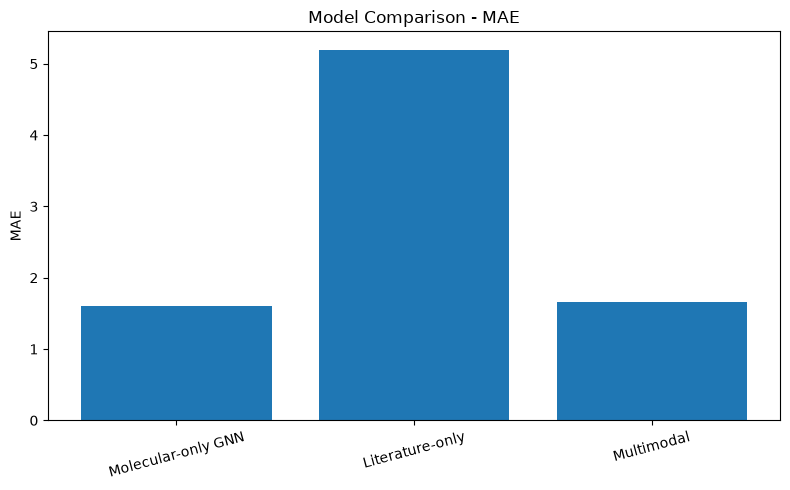

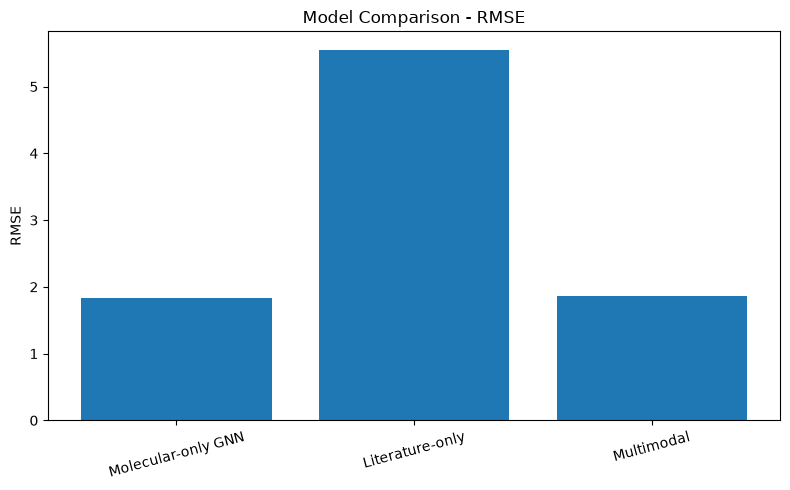

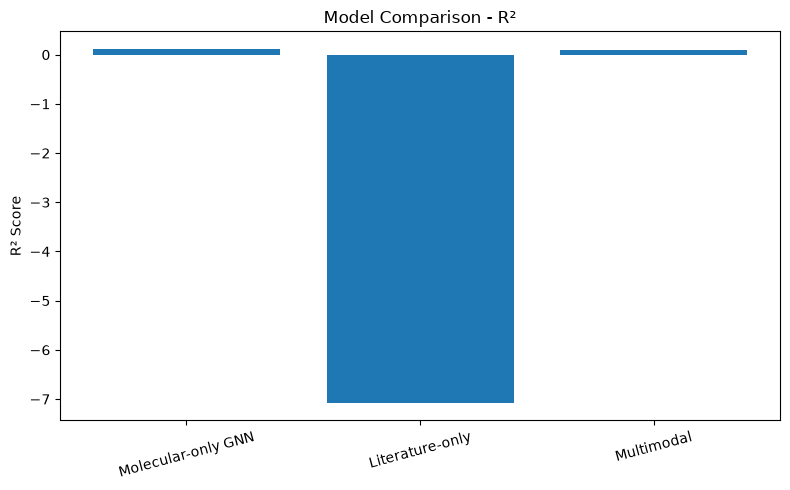

In [19]:
import matplotlib.pyplot as plt

models = [
    "Molecular-only GNN",
    "Literature-only",
    "Multimodal"
]

mae = [1.6072, 5.1950, 1.6603]
rmse = [1.8379, 5.5501, 1.8681]
r2 = [0.1147, -7.0731, 0.0854]


# MAE Chart
plt.figure(figsize=(8, 5))
plt.bar(models, mae)
plt.ylabel("MAE")
plt.title("Model Comparison - MAE")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


# RMSE Chart
plt.figure(figsize=(8, 5))
plt.bar(models, rmse)
plt.ylabel("RMSE")
plt.title("Model Comparison - RMSE")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


# R² Chart
plt.figure(figsize=(8, 5))
plt.bar(models, r2)
plt.ylabel("R² Score")
plt.title("Model Comparison - R²")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [20]:
import pandas as pd

results_df = pd.DataFrame({
    "Model": [
        "Molecular-only GNN",
        "Literature-only",
        "Multimodal"
    ],
    "MAE": [
        1.6072,
        5.1950,
        1.6603
    ],
    "RMSE": [
        1.8379,
        5.5501,
        1.8681
    ],
    "R2": [
        0.1147,
        -7.0731,
        0.0854
    ]
})

results_df

,Model,MAE,RMSE,R2
0,Molecular-only GNN,1.6072,1.8379,0.1147
1,Literature-only,5.1950,5.5501,-7.0731
2,Multimodal,1.6603,1.8681,0.0854


In [21]:
results_df.style.hide(axis="index")

Model,MAE,RMSE,R2
Molecular-only GNN,1.607200,1.837900,0.114700
Literature-only,5.195000,5.550100,-7.073100
Multimodal,1.660300,1.868100,0.085400
